# Pronóstico de Ventas para la Planificación del Abastecimiento — Asertia Comercial (Línea Ferrero)

**Proyecto Capstone — Maestría en Inteligencia de Negocios y Ciencia de Datos, UDLA**

Autor: Michael Wladimir Romero Nole · Tutor: Manuel Eugenio Morocho Cayamcela

Este cuaderno desarrolla el análisis de la tesis: construye el panel mensual de ventas por agencia, grupo de cliente y marca, explora los datos, entrena un modelo Random Forest y lo compara con una regresión lineal, XGBoost y reglas simples de pronóstico, y termina con el pronóstico de septiembre a noviembre de 2026 que alimenta la herramienta en Excel.

| Sección | Contenido | Tablas y figuras de la tesis |
|---|---|---|
| 1 | Carga de datos | Tabla 3 |
| 2 | Limpieza, pre-procesamiento y transformación | Tabla 3 |
| 3 | Análisis exploratorio y pruebas estadísticas | Tablas 4 y 5, Figuras 1 a 5 |
| 4 | Selección y entrenamiento de los modelos | Tabla 6 |
| 5 | Resultados | Tablas 7 a 10, Figuras 6 a 10 |
| 6 | Interpretación de resultados | Tabla 11, Figura 11 |
| 7 | Implicaciones para la organización | Tablas 12 y 13, Figura 12 |

> **Nota:** Si se ejecuta en Google Colab, subir a la sesión los archivos `.csv` (o descomentar las líneas de `drive.mount` y ajustar la ruta). Para ejecución local, dejar `ruta = ''` con los archivos en la misma carpeta del cuaderno. La ejecución completa tarda unos 10 a 20 minutos por la búsqueda de hiperparámetros.

## 1. Carga de datos

Los datos provienen del sistema JD Edwards de Asertia Comercial: una fila por línea de factura, de enero de 2024 a agosto de 2026 (1 248 487 registros). Esa extracción es de uso interno y tiene nombres de clientes y vendedores, por lo que **no se publica**. El repositorio incluye solo el panel mensual agregado por agencia, grupo de cliente y marca, que es la base de todo el análisis. Las celdas de la sección 2 muestran cómo se construyó ese panel y solo se ejecutan si los archivos originales están disponibles.

In [1]:
# =========================================
# 1.1 Importación de librerías
# =========================================
import os
import time
import itertools
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# Librerías que no siempre vienen instaladas en Colab
try:
    import xgboost as xgb
    import statsmodels.api as sm
except ImportError:
    get_ipython().system('pip install -q xgboost statsmodels openpyxl')
    import xgboost as xgb
    import statsmodels.api as sm

SEED = 42                              # semilla fija para que los resultados se repitan
os.makedirs('figuras', exist_ok=True)  # aquí se guardan las figuras
os.makedirs('salidas', exist_ok=True)  # aquí se guardan las tablas y el Excel

In [2]:
# =========================================
# 1.2 Ubicación de los archivos
# =========================================
# Opción A: Google Colab con Google Drive (descomentar si aplica)
# from google.colab import drive
# drive.mount('/content/drive')
# ruta = '/content/drive/MyDrive/Proyecto_Capstone/'

# Opción B: archivos en la misma carpeta del cuaderno (o subidos a la sesión de Colab)
ruta = ''

# Opción C: leer directamente desde GitHub (cambiar USUARIO y REPOSITORIO)
# ruta = 'https://raw.githubusercontent.com/USUARIO/REPOSITORIO/main/'

# =========================================
# 1.3 Estilo de los gráficos
# =========================================
plt.rcParams.update({'font.family': 'STIXGeneral', 'mathtext.fontset': 'stix', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110,
                     'savefig.dpi': 220, 'savefig.bbox': 'tight', 'legend.frameon': False})
AZUL, NARANJA, VERDE, AMARILLO = '#0072B2', '#D55E00', '#009E73', '#E69F00'
CELESTE, GRIS, ROSA = '#56B4E9', '#7f7f7f', '#CC79A7'

def coma(v, dec=1):
    """Número con coma decimal y punto de miles (formato de la tesis)."""
    return f'{v:,.{dec}f}'.replace(',', '§').replace('.', ',').replace('§', '.')

def fmt(dec=1):
    return FuncFormatter(lambda v, _: coma(v, dec))

def cuadricula(ax, eje='y'):
    ax.grid(axis=eje, color='#e6e6e6', lw=.8)
    ax.set_axisbelow(True)

def guardar(fig, nombre):
    fig.savefig(f'figuras/{nombre}.png')
    plt.show()

## 2. Limpieza, pre-procesamiento y transformación de datos (Tabla 3)

Cada fila de la extracción es una línea de factura. El procesamiento sigue este orden: se clasifica a cada cliente en uno de cinco grupos según la letra de su código de tipo de establecimiento, se suman las unidades por mes, agencia, grupo y marca, y se completan con cero los meses sin ventas. Las devoluciones (unidades negativas) se conservan y se compensan al agregar; los netos mensuales negativos se llevan a cero. Los duplicados exactos no se eliminan.

In [3]:
# =========================================
# 2.1 Clasificación de los clientes por grupo
# =========================================
def grupo_cliente(codigo):
    c = str(codigo).strip()
    l = c[:1]
    if l == 'C':
        return 'Cobertura'
    if l == 'F' or c == 'J02':
        return 'Retail'
    if l in ('M', 'A'):
        return 'Mayorista'
    if l == 'D':
        return 'Subdistribuidor'
    if c in ('K02', 'K09'):
        return 'Retail'
    if c == 'K08':
        return 'Farmaenlace'
    if c == 'K15':
        return 'Mayorista'
    return None

# =========================================
# 2.2 Construcción del panel mensual (solo si están los archivos originales)
# =========================================
archivos_crudos = ['Venta_2024.xlsx', 'Venta_2025.xlsx', 'Venta_2026.xlsx']

if all(os.path.exists(ruta + f) for f in archivos_crudos):
    columnas = ['agencia', 'cd', 'fecha', 'vendedor', 'id_cliente', 'cliente', 'tipo_est',
                'cod_tipo', 'cod_prod', 'producto', 'marca', 'venta', 'unid']
    crudo = pd.concat([pd.read_excel(ruta + f).set_axis(columnas, axis=1) for f in archivos_crudos],
                      ignore_index=True)
    print(f"Registros: {len(crudo):,} · duplicados exactos: {crudo.duplicated().sum():,}")
    print(f"Devoluciones: {(crudo.unid < 0).sum():,} registros ({crudo.loc[crudo.unid < 0, 'unid'].sum():,.0f} unidades)")

    crudo['grupo'] = crudo.cod_tipo.map(grupo_cliente)
    crudo['mes'] = crudo.fecha.dt.to_period('M').dt.to_timestamp()

    # Agregación mensual por agencia, grupo y marca
    g = crudo.groupby(['agencia', 'grupo', 'marca', 'mes'], as_index=False).agg(
        unidades=('unid', 'sum'), venta_neta=('venta', 'sum'))
    print('Netos mensuales negativos llevados a cero:', (g.unidades < 0).sum())
    g.loc[g.unidades < 0, 'unidades'] = 0

    # Se completan con cero los meses sin ventas de cada serie
    meses = pd.date_range('2024-01-01', '2026-08-01', freq='MS')
    claves = g[['agencia', 'grupo', 'marca']].drop_duplicates()
    panel_nuevo = (claves.merge(pd.DataFrame({'mes': meses}), how='cross')
                         .merge(g, on=['agencia', 'grupo', 'marca', 'mes'], how='left'))
    panel_nuevo[['unidades', 'venta_neta']] = panel_nuevo[['unidades', 'venta_neta']].fillna(0)
    panel_nuevo = panel_nuevo.sort_values(['agencia', 'grupo', 'marca', 'mes']).reset_index(drop=True)
    panel_nuevo.to_csv('panel_mensual.csv', index=False)

    # Meses con compra por par cliente-marca (para la Figura 5)
    pares_nuevo = crudo.groupby(['id_cliente', 'marca']).mes.nunique().value_counts().sort_index()
    pares_nuevo.rename_axis('meses_con_compra').reset_index(name='pares_cliente_marca') \
               .to_csv('meses_con_compra_cliente_marca.csv', index=False)

    # Precio medio por unidad display en 2026 (líneas con venta y unidades positivas)
    d26 = crudo[(crudo.fecha.dt.year == 2026) & (crudo.venta > 0) & (crudo.unid > 0)]
    (d26.groupby('marca').venta.sum() / d26.groupby('marca').unid.sum()).round(4) \
        .rename('precio_medio_2026').reset_index().to_csv('precios_medios_2026.csv', index=False)
    ruta = ''   # a partir de aquí se leen los archivos recién creados
else:
    print('No están los archivos originales de JD Edwards (son de uso interno): se usa el panel publicado.')

No están los archivos originales de JD Edwards (son de uso interno): se usa el panel publicado.


**Lectura del panel mensual**

El panel tiene una fila por serie (agencia × grupo de cliente × marca) y mes. Se agregan el número de mes calendario y un índice de tiempo que vale 0 en enero de 2024.

In [4]:
# =========================================
# 2.3 Lectura del panel y vista preliminar
# =========================================
panel = pd.read_csv(ruta + 'panel_mensual.csv', parse_dates=['mes'])
panel['serie'] = panel.agencia + '|' + panel.grupo + '|' + panel.marca
panel['t'] = (panel.mes.dt.year - 2024) * 12 + panel.mes.dt.month - 1   # 0 = enero de 2024
panel['mes_cal'] = panel.mes.dt.month

print(f"Dimensiones del panel: {panel.shape[0]:,} filas x {panel.shape[1]} columnas")
print(f"Series: {panel.serie.nunique()} · Agencias: {panel.agencia.nunique()} · "
      f"Grupos: {panel.grupo.nunique()} · Marcas: {panel.marca.nunique()}")
print(f"Periodo: {panel.mes.min():%Y-%m} a {panel.mes.max():%Y-%m}")
print(f"Meses sin venta (ceros): {(panel.unidades == 0).mean() * 100:.1f} %")
panel.head()

Dimensiones del panel: 9,504 filas x 9 columnas
Series: 297 · Agencias: 8 · Grupos: 5 · Marcas: 9
Periodo: 2024-01 a 2026-08
Meses sin venta (ceros): 15.9 %


,agencia,grupo,marca,mes,unidades,venta_neta,serie,t,mes_cal
0,AMBATO,Cobertura,HANUTA,2024-01-01,656.0,2905.21,AMBATO|Cobertura|HANUTA,0,1
1,AMBATO,Cobertura,HANUTA,2024-02-01,800.0,3544.12,AMBATO|Cobertura|HANUTA,1,2
2,AMBATO,Cobertura,HANUTA,2024-03-01,686.0,3041.69,AMBATO|Cobertura|HANUTA,2,3
3,AMBATO,Cobertura,HANUTA,2024-04-01,725.0,3214.88,AMBATO|Cobertura|HANUTA,3,4
4,AMBATO,Cobertura,HANUTA,2024-05-01,954.0,4237.41,AMBATO|Cobertura|HANUTA,4,5


## 3. Análisis exploratorio y pruebas estadísticas

Se revisa el volumen total, la estacionalidad, la concentración de las ventas, la forma de la variable objetivo y la relación de la demanda con sus propios rezagos. Estas revisiones justifican la elección del modelo.

In [5]:
# =========================================
# 3.1 Estadísticos descriptivos del volumen total
# =========================================
tot = panel.groupby('mes').unidades.sum()
print('=== VOLUMEN TOTAL MENSUAL ===')
print(f'Promedio mensual: {tot.mean():,.0f} unidades')
print(f'Coeficiente de variación: {tot.std() / tot.mean() * 100:.1f} %')

base = tot[tot.index.year.isin([2024, 2025])]
indice = (base.groupby(base.index.month).mean() / base.mean()).round(2)
print('\nÍndice estacional (promedio 2024-2025 = 1):')
print(indice.to_dict())
print(f"\nJunio de 2026 frente a mayo: {tot['2026-06-01'] / tot['2026-05-01'] - 1:+.1%} "
      f"({tot['2026-05-01']:,.0f} → {tot['2026-06-01']:,.0f} unidades)")
print(f"Junio de 2025 frente a mayo: {tot['2025-06-01'] / tot['2025-05-01'] - 1:+.1%}")

=== VOLUMEN TOTAL MENSUAL ===
Promedio mensual: 249,904 unidades
Coeficiente de variación: 11.4 %

Índice estacional (promedio 2024-2025 = 1):
{1: 1.1, 2: 1.02, 3: 1.02, 4: 1.17, 5: 1.09, 6: 0.88, 7: 0.87, 8: 0.89, 9: 0.9, 10: 0.96, 11: 1.12, 12: 0.97}

Junio de 2026 frente a mayo: -24.8% (268,675 → 202,057 unidades)
Junio de 2025 frente a mayo: -24.2%


**Figura 1. Serie total mensual**

El volumen total es relativamente estable pero tiene un patrón anual: baja de junio a septiembre y sube en abril y noviembre. La caída de junio de 2026 (−24,8 %) es comparable con la de junio de 2025.

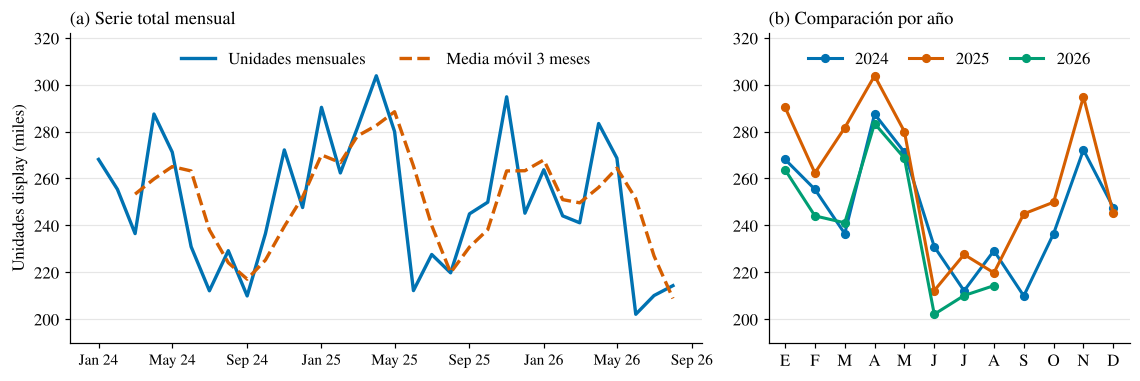

In [6]:
# =========================================
# 3.2 Figura 1: serie total mensual y comparación por año
# =========================================
fig, (a, b) = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={'width_ratios': [1.75, 1]})

a.plot(tot.index, tot / 1e3, color=AZUL, lw=2.2, label='Unidades mensuales')
a.plot(tot.index, tot.rolling(3).mean() / 1e3, color=NARANJA, lw=2.2, ls='--', label='Media móvil 3 meses')
a.set_ylabel('Unidades display (miles)')
a.set_title('(a) Serie total mensual', loc='left', fontsize=12)
a.set_ylim(190, 322)
a.legend(ncol=2, loc='upper center', bbox_to_anchor=(.5, .99))
cuadricula(a)
marcas_x = pd.date_range('2024-01-01', '2026-09-01', freq='4MS')
a.set_xticks(marcas_x)
a.set_xticklabels([x.strftime('%b %y') for x in marcas_x], fontsize=10)

for anio, color in zip((2024, 2025, 2026), (AZUL, NARANJA, VERDE)):
    s = tot[tot.index.year == anio]
    b.plot(s.index.month, s / 1e3, color=color, lw=2, marker='o', ms=5, label=str(anio))
b.set_xticks(range(1, 13))
b.set_xticklabels(list('EFMAMJJASOND'))
b.set_ylim(190, 322)
b.set_title('(b) Comparación por año', loc='left', fontsize=12)
b.legend(ncol=3, loc='upper center', bbox_to_anchor=(.5, .99), columnspacing=1.2)
cuadricula(b)
fig.tight_layout()
guardar(fig, 'figura01_serie_total')

**Figura 2. Concentración de las ventas**

Las ventas se concentran en pocas marcas, en Quito y en los subdistribuidores y mayoristas. Esa concentración hace que los errores en pocas series pesen mucho en las métricas absolutas, y es una razón para reportar también el WAPE.

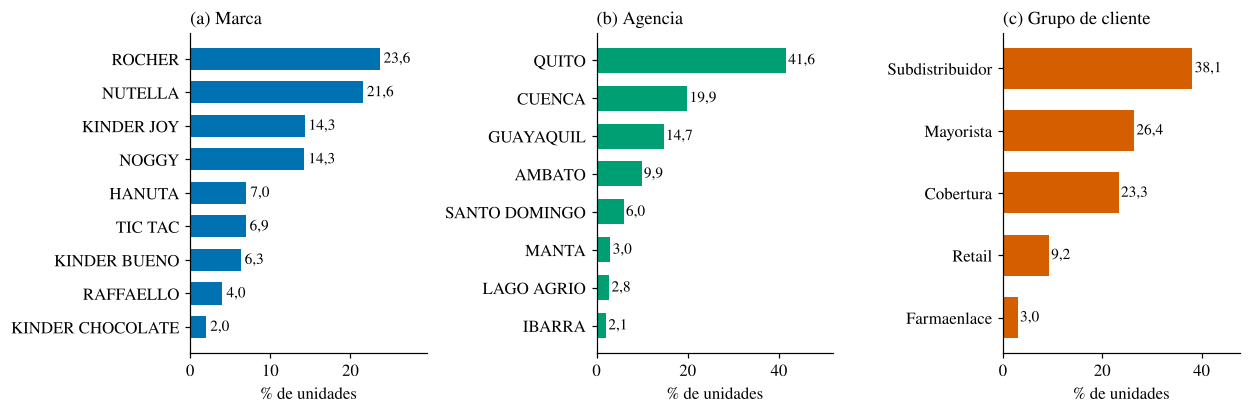

Rocher + Nutella: 45.2 % de las unidades


In [7]:
# =========================================
# 3.3 Figura 2: participación en las unidades por marca, agencia y grupo de cliente
# =========================================
def participacion(columna):
    return (panel.groupby(columna).unidades.sum() / panel.unidades.sum() * 100).sort_values()

fig, axs = plt.subplots(1, 3, figsize=(11.5, 3.9))
for ax, col, color, titulo in zip(axs, ['marca', 'agencia', 'grupo'], [AZUL, VERDE, NARANJA],
                                  ['(a) Marca', '(b) Agencia', '(c) Grupo de cliente']):
    s = participacion(col)
    ax.barh(s.index, s.values, color=color, height=.66)
    for i, v in enumerate(s.values):
        ax.text(v + .5, i, coma(v), va='center', fontsize=10)
    ax.set_title(titulo, loc='left', fontsize=12)
    ax.set_xlabel('% de unidades')
    ax.set_xlim(0, s.max() * 1.25)
fig.tight_layout()
guardar(fig, 'figura02_participacion')

print('Rocher + Nutella:', f"{participacion('marca').tail(2).sum():.1f} % de las unidades")

**Figura 3. Distribución de la variable objetivo**

La demanda mensual por serie es muy asimétrica: la media (841) es mucho mayor que la mediana (183) y hay muchos meses con cero. Los grupos de cliente difieren en nivel y dispersión.

=== VARIABLE OBJETIVO (unidades por serie y mes) ===
Media: 841 · Mediana: 183 · Asimetría: 4.6
                 median     std
grupo                          
Cobertura         206.0  1630.0
Farmaenlace       625.0   926.0
Mayorista         532.0  1210.0
Retail              8.0  1235.0
Subdistribuidor   167.0  2581.0


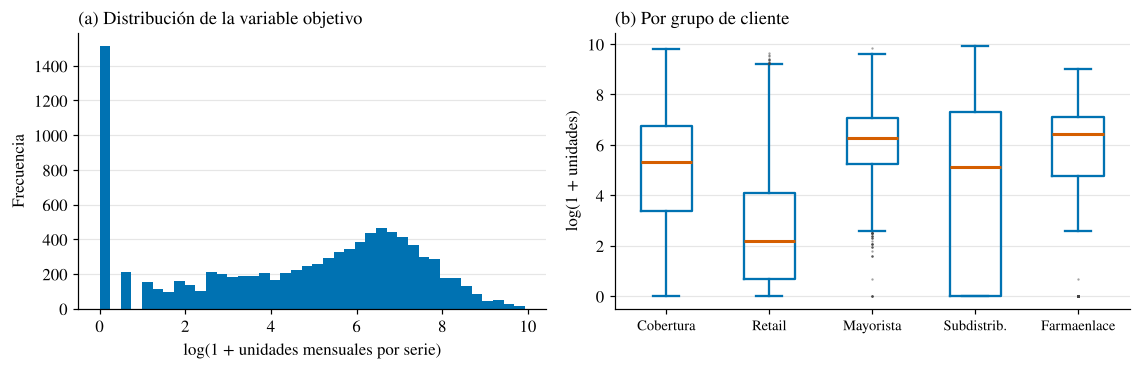

In [8]:
# =========================================
# 3.4 Figura 3: distribución de la demanda y por grupo de cliente
# =========================================
panel['lu'] = np.log1p(panel.unidades)    # log(1 + unidades) para poder graficar los ceros

print('=== VARIABLE OBJETIVO (unidades por serie y mes) ===')
print(f'Media: {panel.unidades.mean():.0f} · Mediana: {panel.unidades.median():.0f} · '
      f'Asimetría: {stats.skew(panel.unidades):.1f}')
print(panel.groupby('grupo').unidades.agg(['median', 'std']).round(0))

fig, (a, b) = plt.subplots(1, 2, figsize=(10.5, 3.5), gridspec_kw={'width_ratios': [1, 1.1]})
a.hist(panel.lu, bins=40, color=AZUL)
a.set_xlabel('log(1 + unidades mensuales por serie)')
a.set_ylabel('Frecuencia')
a.set_title('(a) Distribución de la variable objetivo', loc='left', fontsize=12)
cuadricula(a)

orden = ['Cobertura', 'Retail', 'Mayorista', 'Subdistribuidor', 'Farmaenlace']
b.boxplot([panel.loc[panel.grupo == g, 'lu'] for g in orden], widths=.5,
          medianprops=dict(color=NARANJA, lw=2), boxprops=dict(color=AZUL, lw=1.5),
          whiskerprops=dict(color=AZUL, lw=1.5), capprops=dict(color=AZUL, lw=1.5),
          flierprops=dict(marker='.', ms=3, markerfacecolor='#444', markeredgecolor='none', alpha=.5))
b.set_xticklabels(['Cobertura', 'Retail', 'Mayorista', 'Subdistrib.', 'Farmaenlace'])
b.set_ylabel('log(1 + unidades)')
b.set_title('(b) Por grupo de cliente', loc='left', fontsize=12)
b.tick_params(axis='x', labelsize=9.5)
cuadricula(b)
fig.tight_layout()
guardar(fig, 'figura03_distribucion')

**Figura 4. Correlación con los rezagos**

Se calculan, por serie, los rezagos de 1 a 3 meses y el promedio móvil de 3 meses usando solo meses anteriores. Al perder los tres primeros meses quedan **8 613 observaciones**. La correlación de Spearman de la demanda con sus rezagos es de 0,92 a 0,93, mientras que el mes calendario y el índice de tiempo casi no se correlacionan con la demanda del conjunto agrupado.

Observaciones con al menos tres meses de historia: 8,613


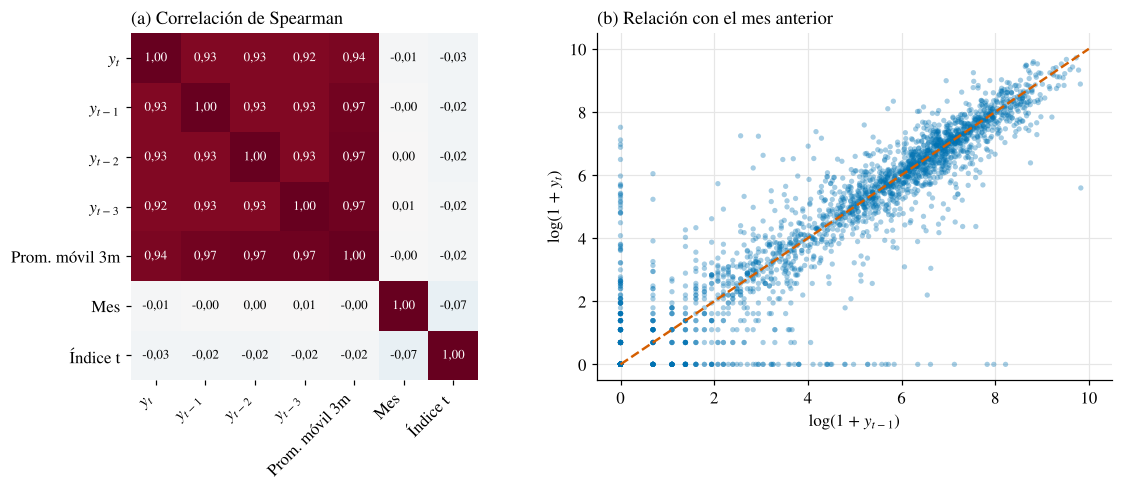

Spearman entre y_t y y_t-1: 0.93
Pearson entre y_t y y_t-1:  0.84


In [9]:
# =========================================
# 3.5 Figura 4: variables derivadas y correlación de Spearman
# =========================================
agrupado = panel.groupby('serie').unidades
eda = panel.copy()
for k in (1, 2, 3):
    eda[f'y_t-{k}'] = agrupado.shift(k)
eda['Prom. móvil 3m'] = eda[['y_t-1', 'y_t-2', 'y_t-3']].mean(axis=1)
eda = eda[eda.t >= 3].copy()      # se pierden los 3 primeros meses

print(f'Observaciones con al menos tres meses de historia: {len(eda):,}')

columnas_corr = ['unidades', 'y_t-1', 'y_t-2', 'y_t-3', 'Prom. móvil 3m', 'mes_cal', 't']
etiquetas = ['$y_t$', '$y_{t-1}$', '$y_{t-2}$', '$y_{t-3}$', 'Prom. móvil 3m', 'Mes', 'Índice t']
C = eda[columnas_corr].corr(method='spearman').values

fig, (a, b) = plt.subplots(1, 2, figsize=(10.8, 4.6), gridspec_kw={'width_ratios': [1, 1.15]})
a.imshow(C, cmap='RdBu_r', vmin=-1, vmax=1)
a.set_xticks(range(7))
a.set_yticks(range(7))
a.set_xticklabels(etiquetas, rotation=45, ha='right')
a.set_yticklabels(etiquetas)
for i in range(7):
    for j in range(7):
        a.text(j, i, f'{C[i, j]:.2f}'.replace('.', ','), ha='center', va='center', fontsize=8.5,
               color='white' if abs(C[i, j]) > .6 else 'black')
for borde in a.spines.values():
    borde.set_visible(False)
a.set_title('(a) Correlación de Spearman', loc='left', fontsize=12)

muestra = eda.sample(2500, random_state=SEED)
b.scatter(np.log1p(muestra['y_t-1']), np.log1p(muestra.unidades), s=12, color=AZUL, alpha=.35, edgecolor='none')
b.plot([0, 10], [0, 10], color=NARANJA, ls='--', lw=1.6)
b.set_xlabel('log(1 + $y_{t-1}$)')
b.set_ylabel('log(1 + $y_t$)')
b.set_title('(b) Relación con el mes anterior', loc='left', fontsize=12)
cuadricula(b, 'both')
fig.tight_layout()
guardar(fig, 'figura04_correlacion')

print('Spearman entre y_t y y_t-1:', round(stats.spearmanr(eda.unidades, eda['y_t-1'])[0], 2))
print('Pearson entre y_t y y_t-1: ', round(np.corrcoef(eda.unidades, eda['y_t-1'])[0, 1], 2))

**Figura 5. Por qué no se modela por cliente**

A nivel cliente-marca la demanda es demasiado intermitente: la mediana de los pares compró en 3 de los 32 meses. Por eso la unidad de análisis es la combinación de agencia, grupo de cliente y marca, que además es el nivel en que se planifica la reposición. Esta figura usa la distribución calculada con la extracción por cliente.

135,836 pares cliente-marca · mediana: 3 meses · 56.4% compró en 3 meses o menos · 2.3% en 24 meses o más


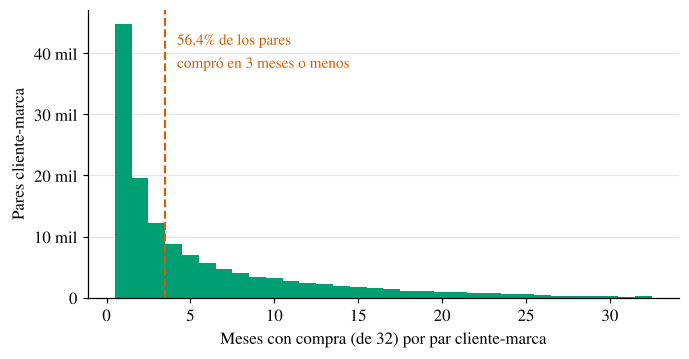

In [10]:
# =========================================
# 3.6 Figura 5: meses con compra por par cliente-marca
# =========================================
pares = pd.read_csv(ruta + 'meses_con_compra_cliente_marca.csv')
n_pares = pares.pares_cliente_marca.sum()
acumulado = pares.pares_cliente_marca.cumsum() / n_pares
mediana = int(pares.meses_con_compra[acumulado >= .5].iloc[0])
p3 = pares.loc[pares.meses_con_compra <= 3, 'pares_cliente_marca'].sum() / n_pares
p24 = pares.loc[pares.meses_con_compra >= 24, 'pares_cliente_marca'].sum() / n_pares
print(f'{n_pares:,} pares cliente-marca · mediana: {mediana} meses · '
      f'{p3:.1%} compró en 3 meses o menos · {p24:.1%} en 24 meses o más')

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.bar(pares.meses_con_compra, pares.pares_cliente_marca, width=1, color=VERDE)
ax.axvline(3.5, color=NARANJA, ls='--', lw=1.4)
ax.text(4.2, ax.get_ylim()[1] * .80, f'{p3 * 100:.1f}% de los pares\ncompró en 3 meses o menos'.replace('.', ','),
        color=NARANJA, fontsize=10)
ax.set_xlabel('Meses con compra (de 32) por par cliente-marca')
ax.set_ylabel('Pares cliente-marca')
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{int(v / 1000)} mil' if v else '0'))
cuadricula(ax)
fig.tight_layout()
guardar(fig, 'figura05_pares_cliente_marca')

**Pruebas sobre la naturaleza de los datos (Tabla 5)**

Se aplica la prueba de Dickey-Fuller aumentada (constante y rezagos elegidos por AIC) a la serie total y a cada marca, y la prueba RESET de Ramsey a una regresión lineal de $y_t$ sobre sus tres rezagos. La primera revisa si las series son estacionarias; la segunda, si la relación con el pasado es lineal.

In [11]:
# =========================================
# 3.7 Prueba de Dickey-Fuller aumentada (Tabla 5)
# =========================================
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import linear_reset

def prueba_adf(serie):
    estadistico, p, *_ = adfuller(serie.values, regression='c', autolag='AIC')
    return estadistico, p

filas = [('Total',) + prueba_adf(tot)]
por_marca = panel.groupby(['marca', 'mes']).unidades.sum().unstack(0)
for marca in por_marca.columns:
    filas.append((marca.title(),) + prueba_adf(por_marca[marca]))

tabla5 = pd.DataFrame(filas, columns=['Serie mensual', 'Estadístico', 'Valor p'])
tabla5['Estacionaria (5 %)'] = np.where(tabla5['Valor p'] < .05, 'Sí', 'No')
tabla5 = tabla5.sort_values('Estadístico').reset_index(drop=True)
tabla5.to_csv('salidas/tabla05_adf.csv', index=False)
print('=== TABLA 5. DICKEY-FULLER AUMENTADA ===')
print(tabla5.round(3))

# Prueba por serie, en las series con al menos 12 meses con venta
suficientes = [s for s, v in panel.groupby('serie').unidades if (v > 0).sum() >= 12 and v.std() > 0]
estacionarias = [prueba_adf(panel.loc[panel.serie == s, 'unidades'])[1] < .05 for s in suficientes]
print(f'\n{len(suficientes)} series con historia suficiente · {np.mean(estacionarias) * 100:.1f} % estacionarias al 5 %')

# =========================================
# 3.8 Prueba RESET de Ramsey (linealidad)
# =========================================
X_reset = sm.add_constant(eda[['y_t-1', 'y_t-2', 'y_t-3']])
ols = sm.OLS(eda.unidades, X_reset).fit()
reset = linear_reset(ols, power=[2, 3], test_type='fitted', use_f=True)
print(f'RESET de Ramsey: F = {float(reset.statistic):.1f}, p = {float(reset.pvalue):.4f}')

=== TABLA 5. DICKEY-FULLER AUMENTADA ===
      Serie mensual  Estadístico  Valor p Estacionaria (5 %)
0        Kinder Joy       -6.351    0.000                 Sí
1         Raffaello       -4.111    0.001                 Sí
2           Tic Tac       -3.952    0.002                 Sí
3             Total       -3.450    0.009                 Sí
4            Rocher       -3.425    0.010                 Sí
5           Nutella       -1.722    0.420                 No
6  Kinder Chocolate       -1.167    0.688                 No
7             Noggy       -1.030    0.742                 No
8      Kinder Bueno       -0.681    0.852                 No
9            Hanuta        2.253    0.999                 No



254 series con historia suficiente · 70.9 % estacionarias al 5 %
RESET de Ramsey: F = 47.4, p = 0.0000


## 4. Selección y entrenamiento de los modelos (Tabla 6)

El problema es de regresión: predecir una cantidad continua y no negativa por serie y mes. Se elige **Random Forest Regressor** (Breiman, 2001) y se compara con una **regresión lineal** como línea base, con **XGBoost** (Chen y Guestrin, 2016) y con tres reglas simples: el pronóstico ingenuo (repite el mes anterior), el ingenuo estacional (repite el mismo mes del año anterior) y el promedio móvil de 3 meses.

Para cada horizonte (1, 2 y 3 meses) se entrena un **modelo directo**: los rezagos se calculan $h$ meses antes del mes que se predice. La división es cronológica, sin mezclar meses: entrenamiento hasta diciembre de 2025, validación de enero a abril de 2026 y prueba de mayo a agosto de 2026. Los hiperparámetros se eligen **solo con la validación**; con los valores elegidos, cada modelo se reajusta con entrenamiento más validación y se evalúa una única vez en la prueba.

Se prueban tres especificaciones:
- `orig`: variables de la metodología (rezagos 1 a 3, promedio móvil, mes e índice de tiempo), con todo el historial.
- `orig_w12`: las mismas variables, entrenando desde enero de 2025 (la ventana en que existe el rezago de 12 meses), para comparar en igualdad de condiciones.
- `lag12` («Random Forest ampliado»): variables de la metodología más la venta del mismo mes del año anterior, $y_{t-12}$.

In [12]:
# =========================================
# 4.1 Partición temporal y variables
# =========================================
HORIZONTES = (1, 2, 3)
T_ENTRENA_FIN = 23          # t = 23 → diciembre de 2025
T_VALIDA = (24, 27)         # enero a abril de 2026
T_PRUEBA = (28, 31)         # mayo a agosto de 2026

VARIABLES = ['lag1', 'lag2', 'lag3', 'ma3', 'mes_cal', 't']
CATEGORICAS = ['agencia', 'grupo', 'marca']
COLUMNAS_DUMMY = pd.get_dummies(panel[CATEGORICAS]).astype(float).columns

def construir_datos(h):
    """Variables derivadas para el horizonte h; todo se calcula solo con meses anteriores."""
    d = panel.sort_values(['serie', 't']).reset_index(drop=True)
    g = d.groupby('serie').unidades
    for k in range(3):
        d[f'lag{k + 1}'] = g.shift(h + k)           # y(t-h), y(t-h-1), y(t-h-2)
    d['ma3'] = d[['lag1', 'lag2', 'lag3']].mean(axis=1)
    d['lag12'] = g.shift(12)                         # mismo mes del año anterior
    return d

DATOS = {h: construir_datos(h) for h in HORIZONTES}

def particion(h, spec):
    """Devuelve entrenamiento, validación y prueba para el horizonte h y la especificación spec."""
    inicio = 12 if spec in ('lag12', 'orig_w12') else h + 2   # primer mes con todas las variables
    d = DATOS[h][DATOS[h].t >= inicio]
    entrena = d[d.t <= T_ENTRENA_FIN]
    valida = d[(d.t >= T_VALIDA[0]) & (d.t <= T_VALIDA[1])]
    prueba = d[(d.t >= T_PRUEBA[0]) & (d.t <= T_PRUEBA[1])]
    return entrena, valida, prueba

for h in HORIZONTES:
    n_tr, n_va, n_te = [len(x) for x in particion(h, 'orig')]
    print(f'Horizonte {h}: entrenamiento {n_tr:,} · validación {n_va:,} · prueba {n_te:,} observaciones')
print('Entrenamiento a un mes con rezago de 12 meses:', len(particion(1, 'lag12')[0]), 'observaciones')

Horizonte 1: entrenamiento 6,237 · validación 1,188 · prueba 1,188 observaciones
Horizonte 2: entrenamiento 5,940 · validación 1,188 · prueba 1,188 observaciones
Horizonte 3: entrenamiento 5,643 · validación 1,188 · prueba 1,188 observaciones
Entrenamiento a un mes con rezago de 12 meses: 3564 observaciones


In [13]:
# =========================================
# 4.2 Funciones de ajuste y métricas
# =========================================
def matriz(d, spec, lineal=False):
    """Variables numéricas + codificación one-hot de agencia, grupo y marca."""
    cols = [c for c in VARIABLES if not (lineal and c == 'ma3')]   # el promedio móvil es combinación exacta de los rezagos
    if spec == 'lag12':
        cols = cols + ['lag12']
    x = d[cols].reset_index(drop=True)
    dummies = (pd.get_dummies(d[CATEGORICAS]).astype(float)
                 .reindex(columns=COLUMNAS_DUMMY, fill_value=0).reset_index(drop=True))
    return pd.concat([x, dummies], axis=1)

def modelo_rf(p):
    return RandomForestRegressor(n_estimators=300, max_depth=p['max_depth'], min_samples_leaf=p['min_samples_leaf'],
                                 max_features=p['max_features'], random_state=SEED, n_jobs=-1)

def modelo_xgb(p):
    return xgb.XGBRegressor(n_estimators=p['n_estimators'], max_depth=p['max_depth'],
                            learning_rate=p['learning_rate'], random_state=SEED, n_jobs=-1)

def ajustar_predecir(nombre, params, entrena, pred, spec):
    """Ajusta el modelo con 'entrena' y pronostica 'pred'. nombre: 'LR', 'RF' o 'XGB'."""
    y = entrena.unidades.values
    if nombre == 'LR':
        escala = StandardScaler().fit(matriz(entrena, spec, True))     # se ajusta solo con entrenamiento
        lr = LinearRegression().fit(escala.transform(matriz(entrena, spec, True)), y)
        f = lr.predict(escala.transform(matriz(pred, spec, True)))
    else:
        modelo = (modelo_rf if nombre == 'RF' else modelo_xgb)(params).fit(matriz(entrena, spec), y)
        f = modelo.predict(matriz(pred, spec))
    return np.clip(f, 0, None)          # la demanda no puede ser negativa

def metricas(y, f):
    y, f = np.asarray(y, float), np.asarray(f, float)
    e = f - y
    positivos = y > 0                   # el MAPE solo se define cuando y > 0
    return {'MAE': np.abs(e).mean(),
            'RMSE': np.sqrt((e ** 2).mean()),
            'MAPE (%)': 100 * np.mean(np.abs(e[positivos]) / y[positivos]),
            'WAPE': np.abs(e).sum() / y.sum(),
            'Sesgo (%)': 100 * e.sum() / y.sum()}

**Búsqueda de hiperparámetros**

El criterio es el MAE en validación. Para Random Forest se prueban 32 combinaciones con 300 árboles (profundidad máxima de 6, 10, 16 o sin límite; mínimo de 1, 3, 5 o 10 observaciones por hoja; fracción de predictores por partición de 0,5 o 1,0). Para XGBoost se prueban 12 combinaciones (200 o 400 árboles; profundidad de 3, 5 o 7; tasa de aprendizaje de 0,05 o 0,10). Esta celda es la más lenta del cuaderno.

In [14]:
# =========================================
# 4.3 Búsqueda de hiperparámetros (criterio: MAE en validación)
# =========================================
malla_rf = [dict(max_depth=a, min_samples_leaf=b, max_features=c)
            for a, b, c in itertools.product([6, 10, 16, None], [1, 3, 5, 10], [.5, 1.0])]
malla_xgb = [dict(n_estimators=a, max_depth=b, learning_rate=c)
             for a, b, c in itertools.product([200, 400], [3, 5, 7], [.05, .10])]

PARAMS = {}
inicio = time.time()
for h in HORIZONTES:
    entrena, valida, _ = particion(h, 'orig')
    PARAMS[h] = {}
    for nombre, malla in (('RF', malla_rf), ('XGB', malla_xgb)):
        puntajes = []
        for p in malla:
            f = ajustar_predecir(nombre, p, entrena, valida, 'orig')
            puntajes.append((np.abs(f - valida.unidades.values).mean(), p))
        mejor_mae, mejor_p = min(puntajes, key=lambda z: z[0])
        PARAMS[h][nombre] = mejor_p
        PARAMS[h][nombre + '_mae_val'] = mejor_mae
    print(f'Horizonte {h} listo ({time.time() - inicio:.0f} s)')

tabla6 = pd.DataFrame([{
    'Horizonte': f'{h} mes' + ('es' if h > 1 else ''),
    'Random Forest (profundidad, hoja mín., fracción)': f"{PARAMS[h]['RF']['max_depth']}, {PARAMS[h]['RF']['min_samples_leaf']}, {PARAMS[h]['RF']['max_features']}",
    'MAE validación RF': round(PARAMS[h]['RF_mae_val'], 1),
    'XGBoost (árboles, profundidad, tasa)': f"{PARAMS[h]['XGB']['n_estimators']}, {PARAMS[h]['XGB']['max_depth']}, {PARAMS[h]['XGB']['learning_rate']}",
    'MAE validación XGB': round(PARAMS[h]['XGB_mae_val'], 1)} for h in HORIZONTES])
tabla6.to_csv('salidas/tabla06_hiperparametros.csv', index=False)
print('\n=== TABLA 6. HIPERPARÁMETROS ELEGIDOS ===')
tabla6

Horizonte 1 listo (92 s)


Horizonte 2 listo (179 s)


Horizonte 3 listo (261 s)

=== TABLA 6. HIPERPARÁMETROS ELEGIDOS ===


,Horizonte,"Random Forest (profundidad, hoja mín., fracción)",MAE validación RF,"XGBoost (árboles, profundidad, tasa)",MAE validación XGB
0,1 mes,"16, 5, 0.5",317.9,"200, 3, 0.05",326.5
1,2 meses,"10, 3, 0.5",343.1,"200, 3, 0.05",349.3
2,3 meses,"6, 3, 0.5",347.5,"200, 7, 0.05",351.7


**Ajuste final**

Con los hiperparámetros elegidos se ajustan los tres modelos (regresión lineal, Random Forest y XGBoost) en las tres especificaciones y los tres horizontes. Para la validación el modelo se entrena solo con el periodo de entrenamiento; para la prueba, con entrenamiento y validación juntos.

In [15]:
# =========================================
# 4.4 Ajuste de todos los modelos
# =========================================
RES = {}
for h in HORIZONTES:
    for spec in ('orig', 'orig_w12', 'lag12'):
        entrena, valida, prueba = particion(h, spec)
        entrena_valida = pd.concat([entrena, valida])
        for nombre in ('LR', 'RF', 'XGB'):
            p = PARAMS[h].get(nombre)
            RES[(h, spec, nombre)] = {
                'val': ajustar_predecir(nombre, p, entrena, valida, spec),
                'test': ajustar_predecir(nombre, p, entrena_valida, prueba, spec)}

VALIDA = {h: particion(h, 'orig')[1] for h in HORIZONTES}
PRUEBA = {h: particion(h, 'lag12')[2].reset_index(drop=True) for h in HORIZONTES}
yt = {h: PRUEBA[h].unidades.values for h in HORIZONTES}

# Las tres reglas simples (no se entrenan)
BASE = {h: {'Ingenuo (mes anterior)': PRUEBA[h].lag1.values,
            'Ingenuo estacional': PRUEBA[h].lag12.values,
            'Promedio móvil 3': PRUEBA[h].ma3.values} for h in HORIZONTES}
print('Modelos ajustados. Observaciones de prueba:', len(yt[1]))

Modelos ajustados. Observaciones de prueba: 1188


## 5. Resultados

Todas las métricas se calculan en el periodo de prueba (mayo a agosto de 2026, 1 188 observaciones). El MAPE se calcula solo sobre las observaciones con demanda positiva; el WAPE pondera el error por el volumen; el sesgo positivo indica que el modelo pronostica de más.

In [16]:
# =========================================
# 5.1 Tabla 7: desempeño a un mes con las variables de la metodología
# =========================================
filas = {nombre: metricas(yt[1], f) for nombre, f in BASE[1].items()}
filas['Regresión lineal'] = metricas(yt[1], RES[(1, 'orig', 'LR')]['test'])
filas['Random Forest'] = metricas(yt[1], RES[(1, 'orig', 'RF')]['test'])
filas['Gradient boosting (XGBoost)'] = metricas(yt[1], RES[(1, 'orig', 'XGB')]['test'])

tabla7 = pd.DataFrame(filas).T.round(3)
tabla7.to_csv('salidas/tabla07_prueba_un_mes.csv')
print('=== TABLA 7. DESEMPEÑO EN LA PRUEBA A UN MES (variables de la metodología) ===')
print(tabla7)

mae_val = lambda f: np.abs(f - VALIDA[1].unidades.values).mean()
print('\nMAE en validación → Random Forest:', round(mae_val(RES[(1, 'orig', 'RF')]['val']), 1),
      '· promedio móvil:', round(mae_val(VALIDA[1].ma3.values), 1),
      '· ingenuo:', round(mae_val(VALIDA[1].lag1.values), 1))

=== TABLA 7. DESEMPEÑO EN LA PRUEBA A UN MES (variables de la metodología) ===
                                 MAE      RMSE  MAPE (%)   WAPE  Sesgo (%)
Ingenuo (mes anterior)       359.347  1041.725    87.775  0.477      7.730
Ingenuo estacional           326.017   794.769   115.221  0.433      4.963
Promedio móvil 3             323.427   863.084   102.887  0.429     11.606
Regresión lineal             337.131   840.126   242.527  0.447     13.643
Random Forest                323.550   874.669   120.188  0.429     10.667
Gradient boosting (XGBoost)  302.765   806.715   108.404  0.402      3.329

MAE en validación → Random Forest: 317.9 · promedio móvil: 326.2 · ingenuo: 359.8


**Efecto del rezago de 12 meses (Tabla 8)**

La demanda tiene un patrón anual marcado, así que se prueba agregar la venta del mismo mes del año anterior. Esa variable existe solo desde enero de 2025, por lo que la comparación se hace sobre exactamente la misma ventana de entrenamiento (`orig_w12` frente a `lag12`).

In [17]:
# =========================================
# 5.2 Tabla 8: WAPE con y sin el rezago de 12 meses
# =========================================
NOMBRES = {'LR': 'Regresión lineal', 'RF': 'Random Forest', 'XGB': 'Gradient boosting (XGBoost)'}
wape = lambda y, f: metricas(y, f)['WAPE']

filas = []
for nombre in ('LR', 'RF', 'XGB'):
    for h in HORIZONTES:
        yv = VALIDA[h].unidades.values
        filas.append({'Modelo': NOMBRES[nombre],
                      'Horizonte': f'{h} mes' + ('es' if h > 1 else ''),
                      'Validación sin': wape(yv, RES[(h, 'orig_w12', nombre)]['val']),
                      'Validación con': wape(yv, RES[(h, 'lag12', nombre)]['val']),
                      'Prueba sin': wape(yt[h], RES[(h, 'orig_w12', nombre)]['test']),
                      'Prueba con': wape(yt[h], RES[(h, 'lag12', nombre)]['test'])})

tabla8 = pd.DataFrame(filas).round(3)
tabla8.to_csv('salidas/tabla08_efecto_rezago12.csv', index=False)
print('=== TABLA 8. WAPE SIN Y CON EL REZAGO DE 12 MESES ===')
print(tabla8)
print('\nCasos en que el rezago baja el WAPE → validación:', int((tabla8['Validación con'] < tabla8['Validación sin']).sum()),
      'de 9 · prueba:', int((tabla8['Prueba con'] < tabla8['Prueba sin']).sum()), 'de 9')

=== TABLA 8. WAPE SIN Y CON EL REZAGO DE 12 MESES ===
                        Modelo Horizonte  Validación sin  Validación con  \
0             Regresión lineal     1 mes           0.394           0.381   
1             Regresión lineal   2 meses           0.419           0.397   
2             Regresión lineal   3 meses           0.413           0.400   
3                Random Forest     1 mes           0.366           0.346   
4                Random Forest   2 meses           0.390           0.371   
5                Random Forest   3 meses           0.404           0.379   
6  Gradient boosting (XGBoost)     1 mes           0.381           0.366   
7  Gradient boosting (XGBoost)   2 meses           0.413           0.390   
8  Gradient boosting (XGBoost)   3 meses           0.413           0.429   

   Prueba sin  Prueba con  
0       0.445       0.399  
1       0.476       0.417  
2       0.516       0.434  
3       0.439       0.399  
4       0.464       0.426  
5       0.482    

**Comparación final y horizontes de pronóstico (Tabla 9)**

Se compara cada modelo con rezago de 12 meses contra las reglas simples. Las columnas MAE, RMSE, MAPE, WAPE y sesgo corresponden al horizonte de un mes; las dos últimas muestran el WAPE a dos y a tres meses.

In [18]:
# =========================================
# 5.3 Tabla 9: desempeño por modelo y horizonte
# =========================================
filas = {}
for nombre in BASE[1]:
    filas[nombre] = {**metricas(yt[1], BASE[1][nombre]),
                     'WAPE 2 m': wape(yt[2], BASE[2][nombre]), 'WAPE 3 m': wape(yt[3], BASE[3][nombre])}
for nombre in ('LR', 'RF', 'XGB'):
    filas[f'{NOMBRES[nombre]} + rezago 12'] = {**metricas(yt[1], RES[(1, 'lag12', nombre)]['test']),
        'WAPE 2 m': wape(yt[2], RES[(2, 'lag12', nombre)]['test']),
        'WAPE 3 m': wape(yt[3], RES[(3, 'lag12', nombre)]['test'])}

tabla9 = pd.DataFrame(filas).T.round(3)
tabla9.to_csv('salidas/tabla09_modelos_horizontes.csv')
print('=== TABLA 9. DESEMPEÑO EN LA PRUEBA POR MODELO Y HORIZONTE ===')
print(tabla9)
for h in HORIZONTES:
    print(f"Sesgo de Random Forest ampliado a {h} mes(es): {metricas(yt[h], RES[(h, 'lag12', 'RF')]['test'])['Sesgo (%)']:+.1f} %")

=== TABLA 9. DESEMPEÑO EN LA PRUEBA POR MODELO Y HORIZONTE ===
                                             MAE      RMSE  MAPE (%)   WAPE  \
Ingenuo (mes anterior)                   359.347  1041.725    87.775  0.477   
Ingenuo estacional                       326.017   794.769   115.221  0.433   
Promedio móvil 3                         323.427   863.084   102.887  0.429   
Regresión lineal + rezago 12             300.441   748.763   190.766  0.399   
Random Forest + rezago 12                300.448   764.449   116.538  0.399   
Gradient boosting (XGBoost) + rezago 12  309.893   814.043   162.471  0.411   

                                         Sesgo (%)  WAPE 2 m  WAPE 3 m  
Ingenuo (mes anterior)                       7.730     0.489     0.534  
Ingenuo estacional                           4.963     0.433     0.433  
Promedio móvil 3                            11.606     0.467     0.504  
Regresión lineal + rezago 12                 5.993     0.417     0.434  
Random Forest + re

**Figura 6. Demanda total real y pronosticada**

El caso más claro es junio de 2026, cuando la demanda cayó 25 %. El pronóstico ingenuo repite el nivel de mayo y falla; el ingenuo estacional acierta porque junio de 2025 también cayó; Random Forest solo tiene un junio previo en su entrenamiento y no alcanza a aprender el patrón.

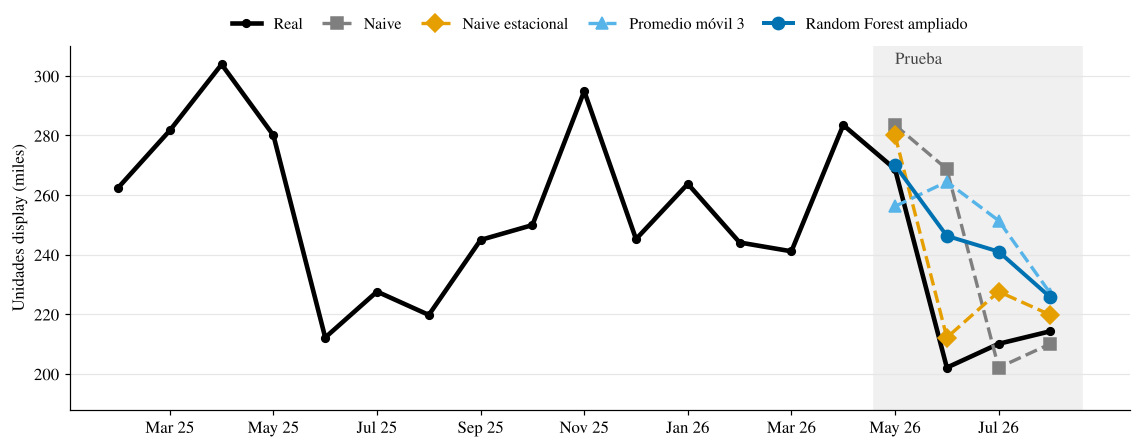

Junio de 2026 → real: 202,057 · ingenuo: 268,675 · Random Forest ampliado: 246,262 (+21.9%) · ingenuo estacional: 212,152


In [19]:
# =========================================
# 5.4 Figura 6: demanda total real y pronosticada a un mes
# =========================================
real = panel.groupby('t').unidades.sum()
meses_prueba = np.arange(28, 32)

def total_por_mes(f):
    return pd.Series(f, index=PRUEBA[1].t.values).groupby(level=0).sum()

series = {'Naive': total_por_mes(BASE[1]['Ingenuo (mes anterior)']),
          'Naive estacional': total_por_mes(BASE[1]['Ingenuo estacional']),
          'Promedio móvil 3': total_por_mes(BASE[1]['Promedio móvil 3']),
          'Random Forest ampliado': total_por_mes(RES[(1, 'lag12', 'RF')]['test'])}
estilos = {'Naive': (GRIS, 's', '--'), 'Naive estacional': (AMARILLO, 'D', '--'),
           'Promedio móvil 3': (CELESTE, '^', '--'), 'Random Forest ampliado': (AZUL, 'o', '-')}
fecha_t = lambda t: pd.Timestamp('2024-01-01') + pd.DateOffset(months=int(t))

fig, ax = plt.subplots(figsize=(10.5, 4.2))
ax.axvspan(27.6, 31.6, color='#f0f0f0', zorder=0)
ax.text(28, 304, 'Prueba', color='#444', fontsize=11)
ax.plot(np.arange(13, 32), real.loc[13:31] / 1e3, color='black', lw=3, marker='o', ms=5, label='Real', zorder=3)
for nombre, s in series.items():
    color, marcador, linea = estilos[nombre]
    ax.plot(meses_prueba, s.loc[meses_prueba] / 1e3, color=color, marker=marcador, ms=8, ls=linea,
            lw=2.6 if nombre == 'Random Forest ampliado' else 2.2, label=nombre, zorder=4)
ax.set_xticks(range(14, 32, 2))
ax.set_xticklabels([fecha_t(t).strftime('%b %y') for t in range(14, 32, 2)])
ax.set_ylabel('Unidades display (miles)')
ax.set_ylim(188, 310)
cuadricula(ax)
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(.5, 1.12), columnspacing=1.2, handlelength=1.8, fontsize=10.5)
fig.tight_layout()
guardar(fig, 'figura06_real_vs_pronostico')

print('Junio de 2026 → real:', f"{real.loc[29]:,.0f}", '· ingenuo:', f"{series['Naive'].loc[29]:,.0f}",
      '· Random Forest ampliado:', f"{series['Random Forest ampliado'].loc[29]:,.0f}",
      f"({series['Random Forest ampliado'].loc[29] / real.loc[29] - 1:+.1%})",
      '· ingenuo estacional:', f"{series['Naive estacional'].loc[29]:,.0f}")

**Figura 7. WAPE por modelo y por horizonte**

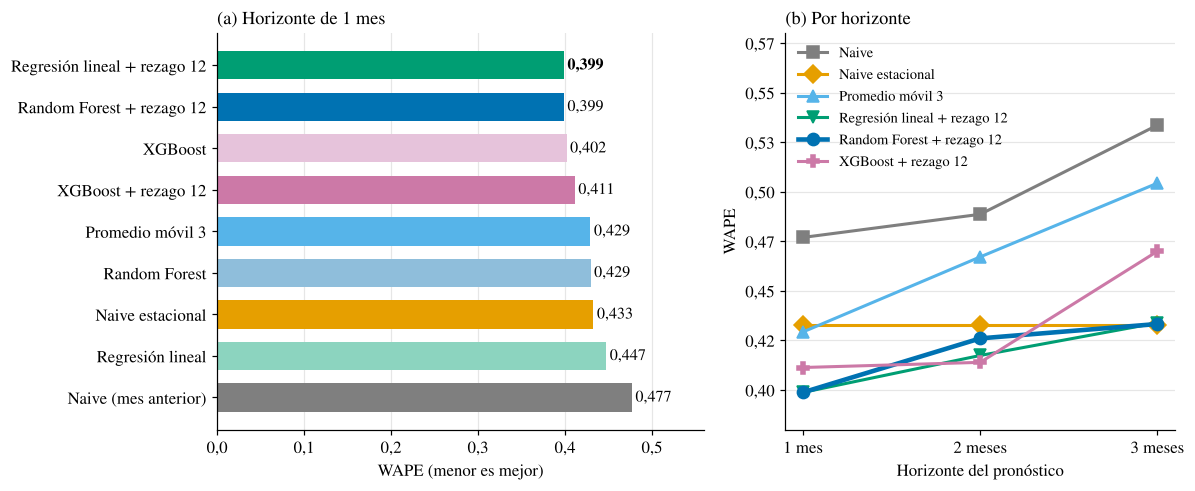

In [20]:
# =========================================
# 5.5 Figura 7: WAPE de los modelos a un mes y por horizonte
# =========================================
wape1 = {'Random Forest + rezago 12': wape(yt[1], RES[(1, 'lag12', 'RF')]['test']),
         'Regresión lineal + rezago 12': wape(yt[1], RES[(1, 'lag12', 'LR')]['test']),
         'XGBoost': wape(yt[1], RES[(1, 'orig', 'XGB')]['test']),
         'Promedio móvil 3': wape(yt[1], BASE[1]['Promedio móvil 3']),
         'XGBoost + rezago 12': wape(yt[1], RES[(1, 'lag12', 'XGB')]['test']),
         'Random Forest': wape(yt[1], RES[(1, 'orig', 'RF')]['test']),
         'Naive estacional': wape(yt[1], BASE[1]['Ingenuo estacional']),
         'Regresión lineal': wape(yt[1], RES[(1, 'orig', 'LR')]['test']),
         'Naive (mes anterior)': wape(yt[1], BASE[1]['Ingenuo (mes anterior)'])}
colores = {'Random Forest + rezago 12': AZUL, 'Regresión lineal + rezago 12': VERDE, 'XGBoost': '#E6C3DB',
           'Promedio móvil 3': CELESTE, 'XGBoost + rezago 12': ROSA, 'Random Forest': '#8FBEDB',
           'Naive estacional': AMARILLO, 'Regresión lineal': '#8CD4BF', 'Naive (mes anterior)': GRIS}
orden = sorted(wape1, key=wape1.get)

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={'width_ratios': [1.25, 1]})
for i, nombre in enumerate(orden):
    a.barh(i, wape1[nombre], color=colores[nombre], height=.68)
    a.text(wape1[nombre] + .004, i, coma(wape1[nombre], 3), va='center', fontsize=10.5,
           fontweight='bold' if i == 0 else 'normal')
a.set_yticks(range(len(orden)))
a.set_yticklabels(orden)
a.invert_yaxis()
a.set_xlim(0, .56)
a.set_xlabel('WAPE (menor es mejor)')
a.set_title('(a) Horizonte de 1 mes', loc='left', fontsize=12)
a.xaxis.set_major_formatter(fmt(1))
cuadricula(a, 'x')

reglas = {'Naive': ('Ingenuo (mes anterior)', GRIS, 's'), 'Naive estacional': ('Ingenuo estacional', AMARILLO, 'D'),
          'Promedio móvil 3': ('Promedio móvil 3', CELESTE, '^')}
for etiqueta, (clave, color, marcador) in reglas.items():
    b.plot([1, 2, 3], [wape(yt[h], BASE[h][clave]) for h in HORIZONTES], color=color, marker=marcador, ms=8, lw=2, label=etiqueta)
for nombre, etiqueta, color, marcador, grosor in (('LR', 'Regresión lineal + rezago 12', VERDE, 'v', 2),
                                                  ('RF', 'Random Forest + rezago 12', AZUL, 'o', 3),
                                                  ('XGB', 'XGBoost + rezago 12', ROSA, 'P', 2)):
    b.plot([1, 2, 3], [wape(yt[h], RES[(h, 'lag12', nombre)]['test']) for h in HORIZONTES],
           color=color, marker=marcador, ms=8, lw=grosor, label=etiqueta)
b.set_xticks([1, 2, 3])
b.set_xticklabels(['1 mes', '2 meses', '3 meses'])
b.set_xlabel('Horizonte del pronóstico')
b.set_ylabel('WAPE')
b.yaxis.set_major_formatter(fmt(2))
b.set_ylim(.38, .58)
b.set_title('(b) Por horizonte', loc='left', fontsize=12)
b.legend(fontsize=9.5, loc='upper left')
cuadricula(b)
fig.tight_layout()
guardar(fig, 'figura07_wape_modelos')

**Nivel de agregación (Figura 8)**

El pronóstico se hace por serie (agencia × grupo × marca). Para ver qué pasa al agregar, se suman los pronósticos de las series y se calcula el WAPE de cada total, mes a mes. El error baja al agregar, pero en agencia y en el total nacional el ingenuo estacional es mejor que el modelo.

=== WAPE SEGÚN EL NIVEL DE AGREGACIÓN ===
                 Naive  Naive estacional  Promedio móvil 3  \
Serie            0.477             0.433             0.429   
Agencia × marca  0.346             0.320             0.319   
Marca            0.268             0.231             0.245   
Agencia          0.183             0.112             0.157   
Total            0.105             0.050             0.144   

                 Random Forest ampliado  
Serie                             0.399  
Agencia × marca                   0.296  
Marca                             0.214  
Agencia                           0.141  
Total                             0.098  


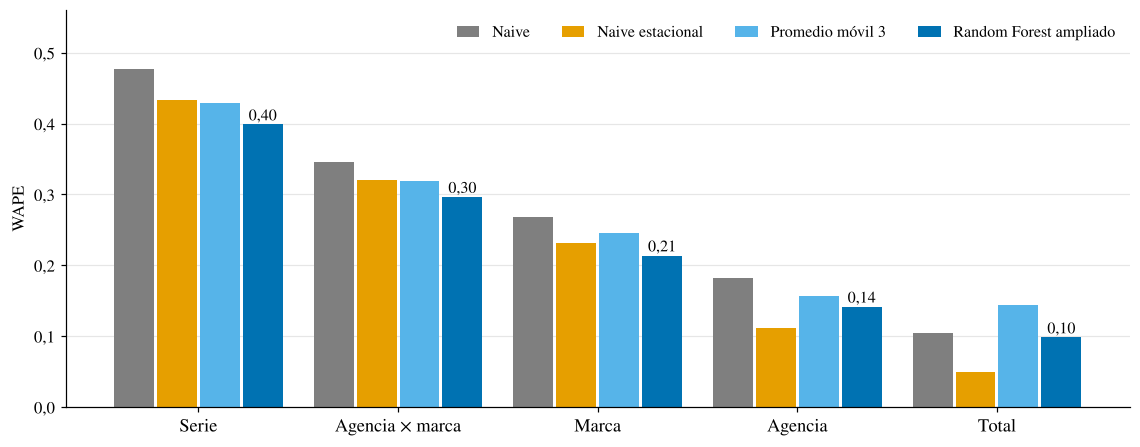

In [21]:
# =========================================
# 5.6 Figura 8: WAPE según el nivel de agregación
# =========================================
resultados = PRUEBA[1].copy()
resultados['Naive'] = BASE[1]['Ingenuo (mes anterior)']
resultados['Naive estacional'] = BASE[1]['Ingenuo estacional']
resultados['Promedio móvil 3'] = BASE[1]['Promedio móvil 3']
resultados['Random Forest ampliado'] = RES[(1, 'lag12', 'RF')]['test']
MODELOS = ['Naive', 'Naive estacional', 'Promedio móvil 3', 'Random Forest ampliado']

def wape_por_nivel(claves):
    g = resultados.groupby(claves + ['t'])[['unidades'] + MODELOS].sum()
    return {m: np.abs(g[m] - g.unidades).sum() / g.unidades.sum() for m in MODELOS}

niveles = {'Serie': ['serie'], 'Agencia × marca': ['agencia', 'marca'], 'Marca': ['marca'],
           'Agencia': ['agencia'], 'Total': []}
agregacion = pd.DataFrame({nombre: wape_por_nivel(c) for nombre, c in niveles.items()}).T
agregacion.round(3).to_csv('salidas/figura08_wape_por_nivel.csv')
print('=== WAPE SEGÚN EL NIVEL DE AGREGACIÓN ===')
print(agregacion.round(3))

fig, ax = plt.subplots(figsize=(10.5, 4.2))
ancho = .2
for j, (modelo, color) in enumerate(zip(MODELOS, [GRIS, AMARILLO, CELESTE, AZUL])):
    x = np.arange(len(agregacion)) + (j - 1.5) * (ancho + .015)
    ax.bar(x, agregacion[modelo], width=ancho, color=color, label=modelo)
    if modelo == 'Random Forest ampliado':
        for xi, v in zip(x, agregacion[modelo]):
            ax.text(xi, v + .006, coma(v, 2), ha='center', fontsize=10.5)
ax.set_xticks(range(len(agregacion)))
ax.set_xticklabels(agregacion.index, fontsize=12)
ax.set_ylabel('WAPE')
ax.yaxis.set_major_formatter(fmt(1))
ax.set_ylim(0, .56)
ax.legend(ncol=4, loc='upper right', fontsize=10.5, handlelength=1.4)
cuadricula(ax)
fig.tight_layout()
guardar(fig, 'figura08_wape_por_nivel')

**Segmentos (Figura 9)**

WAPE por marca y por agencia, calculado por serie y mes. Rocher y Raffaello se pronostican mejor con la venta del mismo mes del año anterior; Hanuta, Noggy y Raffaello son las marcas más difíciles.

=== WAPE por marca ===
                  Naive  Naive estacional  Random Forest ampliado
KINDER CHOCOLATE  0.318             0.403                   0.242
TIC TAC           0.332             0.345                   0.258
KINDER BUENO      0.340             0.380                   0.275
NUTELLA           0.333             0.298                   0.299
KINDER JOY        0.453             0.419                   0.377
ROCHER            0.663             0.358                   0.470
HANUTA            0.563             0.755                   0.566
NOGGY             0.601             0.924                   0.601
RAFFAELLO         0.812             0.470                   0.660
=== WAPE por agencia ===
               Naive  Naive estacional  Random Forest ampliado
LAGO AGRIO     0.341             0.382                   0.355
SANTO DOMINGO  0.295             0.476                   0.360
AMBATO         0.449             0.436                   0.375
IBARRA         0.371             0.456  

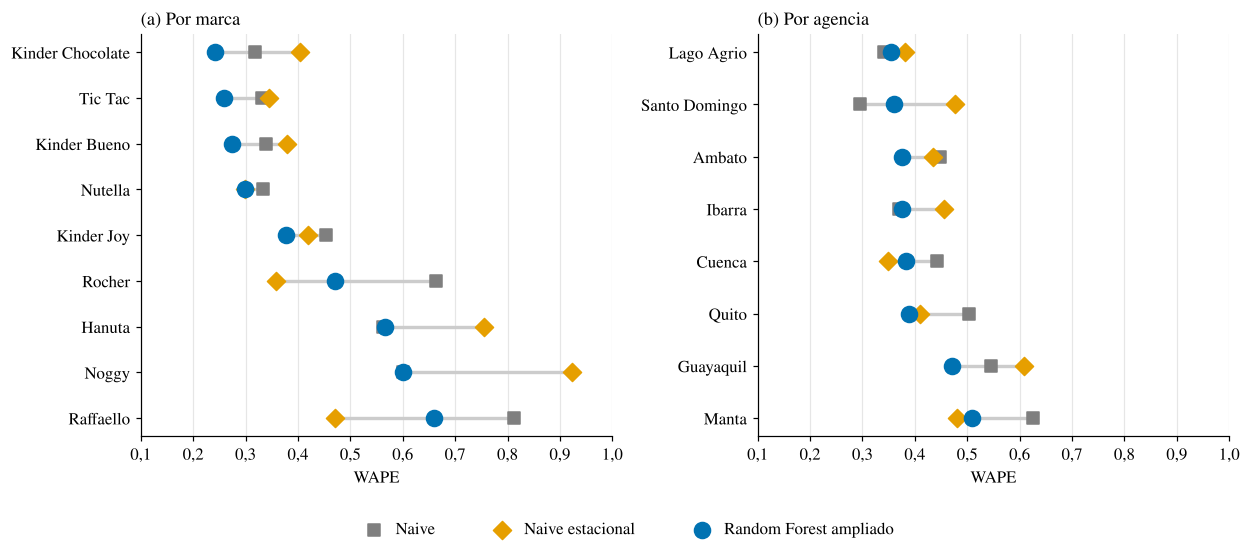

In [22]:
# =========================================
# 5.7 Figura 9: WAPE por marca y por agencia
# =========================================
def wape_por_segmento(columna):
    salida = {}
    for clave, d in resultados.groupby(columna):
        salida[clave] = {m: np.abs(d[m] - d.unidades).sum() / d.unidades.sum()
                         for m in ['Naive', 'Naive estacional', 'Random Forest ampliado']}
    return pd.DataFrame(salida).T.sort_values('Random Forest ampliado')

segmentos = {c: wape_por_segmento(c) for c in ('marca', 'agencia', 'grupo')}
for c in segmentos:
    print(f'=== WAPE por {c} ===')
    print(segmentos[c].round(3))

fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.9))
for ax, c, titulo in zip(axs, ('marca', 'agencia'), ('(a) Por marca', '(b) Por agencia')):
    d = segmentos[c]
    y = np.arange(len(d))
    ax.hlines(y, d.min(axis=1), d.max(axis=1), color='#cccccc', lw=2.2, zorder=1)
    ax.scatter(d['Naive'], y, marker='s', s=70, color=GRIS, label='Naive', zorder=2)
    ax.scatter(d['Naive estacional'], y, marker='D', s=70, color=AMARILLO, label='Naive estacional', zorder=3)
    ax.scatter(d['Random Forest ampliado'], y, marker='o', s=110, color=AZUL, label='Random Forest ampliado', zorder=4)
    ax.set_yticks(y)
    ax.set_yticklabels([k.title() for k in d.index])
    ax.invert_yaxis()
    ax.set_xlim(.1, 1)
    ax.set_xlabel('WAPE')
    ax.xaxis.set_major_formatter(fmt(1))
    ax.set_title(titulo, loc='left', fontsize=12)
    cuadricula(ax, 'x')
handles, etiquetas_leyenda = axs[0].get_legend_handles_labels()
fig.legend(handles, etiquetas_leyenda, ncol=3, loc='lower center', bbox_to_anchor=(.5, -.04), fontsize=11,
           handletextpad=.3, columnspacing=3)
fig.tight_layout(rect=(0, .05, 1, 1))
guardar(fig, 'figura09_wape_por_segmento')

**Réplica del benchmark (Tabla 10 y Figura 10)**

El benchmark principal es Pérez Muso (2025), que comparó regresión lineal, Random Forest y XGBoost para pronosticar la demanda de un repuesto, con partición temporal 80/20 y métricas MAE, RMSE y WAPE. Aquí se aplica el mismo protocolo a las series de Asertia Comercial, con hiperparámetros por defecto. Como las unidades son distintas, no se comparan magnitudes absolutas sino la **mejora relativa** de Random Forest sobre el pronóstico ingenuo.

In [23]:
# =========================================
# 5.8 Réplica del protocolo de Pérez Muso (2025)
# =========================================
def replica(spec):
    d = DATOS[1]
    if spec == 'orig':
        inicio, fin_entrena = 3, 25      # 29 meses utilizables: 23 de entrenamiento y 6 de prueba
    else:
        inicio, fin_entrena = 12, 27     # 20 meses con rezago 12: 16 de entrenamiento y 4 de prueba
    d = d[d.t >= inicio]
    entrena, prueba = d[d.t <= fin_entrena], d[d.t > fin_entrena]

    f = {'Ingenuo': prueba.lag1.values}
    escala = StandardScaler().fit(matriz(entrena, spec, True))
    lr = LinearRegression().fit(escala.transform(matriz(entrena, spec, True)), entrena.unidades)
    f['Regresión lineal'] = np.clip(lr.predict(escala.transform(matriz(prueba, spec, True))), 0, None)
    rf = RandomForestRegressor(random_state=SEED, n_jobs=-1).fit(matriz(entrena, spec), entrena.unidades)
    f['Random Forest'] = np.clip(rf.predict(matriz(prueba, spec)), 0, None)
    gb = xgb.XGBRegressor(random_state=SEED, n_jobs=-1).fit(matriz(entrena, spec), entrena.unidades)
    f['Gradient boosting (XGBoost)'] = np.clip(gb.predict(matriz(prueba, spec)), 0, None)
    print(f'  {spec}: {entrena.t.nunique()} meses de entrenamiento · prueba de {len(prueba):,} observaciones')
    return {nombre: metricas(prueba.unidades.values, pred) for nombre, pred in f.items()}

print('Réplica con hiperparámetros por defecto:')
REPLICA = {'orig': replica('orig'), 'lag12': replica('lag12')}

# Resultados publicados por Pérez Muso (2025)
PEREZ = {'Ingenuo': {'MAE': 4.479, 'RMSE': 7.429, 'WAPE': .908},
         'Random Forest': {'MAE': 3.270, 'RMSE': 5.217, 'WAPE': .663}}

filas = [('Pérez Muso (2025)', k, v) for k, v in PEREZ.items()]
filas += [('Réplica, variables de la metodología', k, v) for k, v in REPLICA['orig'].items()]
filas += [('Réplica, con rezago de 12 meses', k, REPLICA['lag12'][k]) for k in ('Ingenuo', 'Random Forest')]
tabla10 = pd.DataFrame([{'Fuente': f, 'Modelo': m, 'MAE': v['MAE'], 'RMSE': v['RMSE'], 'WAPE': v['WAPE']}
                        for f, m, v in filas]).round(3)
tabla10.to_csv('salidas/tabla10_replica_benchmark.csv', index=False)
print('\n=== TABLA 10. RÉPLICA DEL PROTOCOLO DE PÉREZ MUSO (2025) ===')
print(tabla10)

Réplica con hiperparámetros por defecto:


  orig: 23 meses de entrenamiento · prueba de 1,782 observaciones


  lag12: 16 meses de entrenamiento · prueba de 1,188 observaciones

=== TABLA 10. RÉPLICA DEL PROTOCOLO DE PÉREZ MUSO (2025) ===
                                 Fuente                       Modelo      MAE  \
0                     Pérez Muso (2025)                      Ingenuo    4.479   
1                     Pérez Muso (2025)                Random Forest    3.270   
2  Réplica, variables de la metodología                      Ingenuo  367.455   
3  Réplica, variables de la metodología             Regresión lineal  343.171   
4  Réplica, variables de la metodología                Random Forest  327.143   
5  Réplica, variables de la metodología  Gradient boosting (XGBoost)  337.195   
6       Réplica, con rezago de 12 meses                      Ingenuo  359.347   
7       Réplica, con rezago de 12 meses                Random Forest  312.801   

       RMSE   WAPE  
0     7.429  0.908  
1     5.217  0.663  
2  1063.307  0.461  
3   864.342  0.431  
4   874.295  0.411  
5   956.956  0.

{'Pérez Muso (2025)': [27.0, 29.8, 27.0], 'Réplica en Asertia, diseño base': [np.float64(11.0), np.float64(17.8), np.float64(11.0)], 'Réplica en Asertia, con rezago 12': [np.float64(13.0), np.float64(23.9), np.float64(13.0)]}


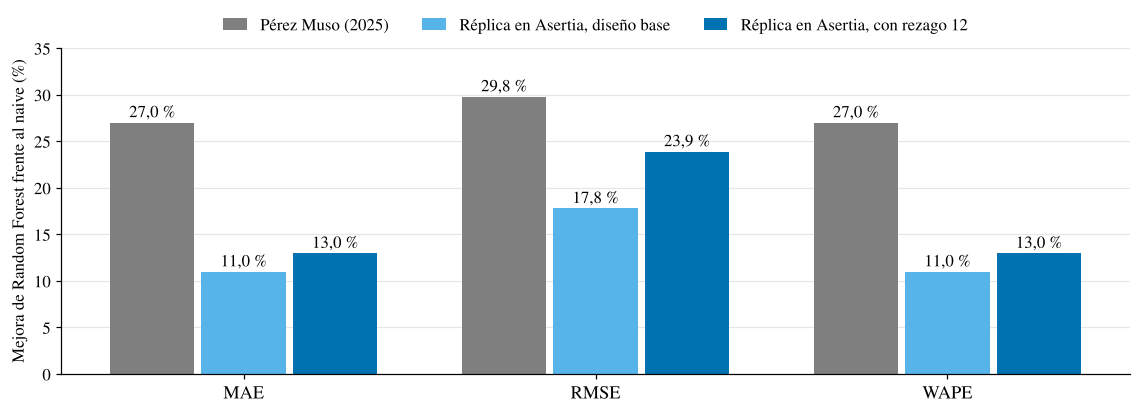

In [24]:
# =========================================
# 5.9 Figura 10: mejora de Random Forest frente al ingenuo
# =========================================
def mejora(r, metrica):
    return (1 - r['Random Forest'][metrica] / r['Ingenuo'][metrica]) * 100

mejoras = {'Pérez Muso (2025)': [mejora(PEREZ, k) for k in ('MAE', 'RMSE', 'WAPE')],
           'Réplica en Asertia, diseño base': [mejora(REPLICA['orig'], k) for k in ('MAE', 'RMSE', 'WAPE')],
           'Réplica en Asertia, con rezago 12': [mejora(REPLICA['lag12'], k) for k in ('MAE', 'RMSE', 'WAPE')]}
print({k: [round(x, 1) for x in v] for k, v in mejoras.items()})

fig, ax = plt.subplots(figsize=(10.5, 3.9))
ancho = .24
for j, (nombre, color) in enumerate(zip(mejoras, [GRIS, CELESTE, AZUL])):
    x = np.arange(3) + (j - 1) * (ancho + .02)
    ax.bar(x, mejoras[nombre], width=ancho, color=color, label=nombre)
    for xi, v in zip(x, mejoras[nombre]):
        ax.text(xi, v + .6, f'{coma(v)} %', ha='center', fontsize=11)
ax.set_xticks(range(3))
ax.set_xticklabels(['MAE', 'RMSE', 'WAPE'], fontsize=12)
ax.set_ylabel('Mejora de Random Forest frente al naive (%)')
ax.set_ylim(0, 35)
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(.5, 1.14), fontsize=11, handlelength=1.4)
cuadricula(ax)
fig.tight_layout()
guardar(fig, 'figura10_replica_benchmark')

## 6. Interpretación de resultados

Esta sección responde a una pregunta: ¿las diferencias entre modelos son reales o producto del azar? Para eso se mide la mejora de un modelo A sobre un modelo B como la reducción relativa del WAPE (ecuación 13): $Mejora = 1 - WAPE_A / WAPE_B$. Se usan dos herramientas:
1. **Intervalo de confianza del 95 % por bootstrap**, con 2 000 remuestreos de las 297 series completas. Conserva la relación entre los meses de una misma serie y pondera por volumen, igual que el WAPE.
2. **Prueba de rangos con signo de Wilcoxon** sobre el MAE de cada serie, que da el mismo peso a las series grandes y a las pequeñas. Por eso las dos pueden dar respuestas distintas.

In [25]:
# =========================================
# 6.1 Tabla 11: mejora de Random Forest ampliado frente a cada comparador
# =========================================
n_series = PRUEBA[1].serie.nunique()
y_serie = PRUEBA[1].unidades.values.reshape(n_series, 4)     # 4 meses de prueba por serie
y_total_serie = y_serie.sum(axis=1)

def error_por_serie(f):
    """Error absoluto total de cada serie en los 4 meses de prueba."""
    return np.abs(np.asarray(f).reshape(n_series, 4) - y_serie).sum(axis=1)

def comparar(error_a, error_b, n_boot=2000):
    rng = np.random.default_rng(SEED)
    idx = rng.integers(0, n_series, size=(n_boot, n_series))     # remuestreo de series completas
    wape_a = error_a[idx].sum(axis=1) / y_total_serie[idx].sum(axis=1)
    wape_b = error_b[idx].sum(axis=1) / y_total_serie[idx].sum(axis=1)
    punto = 1 - (error_a.sum() / y_total_serie.sum()) / (error_b.sum() / y_total_serie.sum())
    inferior, superior = np.percentile(1 - wape_a / wape_b, [2.5, 97.5])
    p_wilcoxon = stats.wilcoxon(error_a, error_b).pvalue
    return punto * 100, inferior * 100, superior * 100, int((error_a < error_b).sum()), int((error_a > error_b).sum()), p_wilcoxon

error_rf = error_por_serie(RES[(1, 'lag12', 'RF')]['test'])
comparadores = {'Ingenuo (mes anterior)': BASE[1]['Ingenuo (mes anterior)'],
                'Promedio móvil 3': BASE[1]['Promedio móvil 3'],
                'Ingenuo estacional': BASE[1]['Ingenuo estacional'],
                'Regresión lineal + rezago 12': RES[(1, 'lag12', 'LR')]['test'],
                'Gradient boosting + rezago 12': RES[(1, 'lag12', 'XGB')]['test'],
                'Random Forest sin rezago 12': RES[(1, 'orig_w12', 'RF')]['test']}   # misma ventana de entrenamiento

filas = []
for nombre, f in comparadores.items():
    mejora_pct, inf, sup, mejor, peor, p = comparar(error_rf, error_por_serie(f))
    filas.append({'Comparador': nombre, 'Mejora (%)': round(mejora_pct, 1), 'IC 95 % inferior': round(inf, 1),
                  'IC 95 % superior': round(sup, 1), 'Series mejor': mejor, 'Series peor': peor,
                  'p (Wilcoxon)': '< 0,001' if p < .001 else f'{p:.3f}'.replace('.', ',')})

tabla11 = pd.DataFrame(filas)
tabla11.to_csv('salidas/tabla11_inferencia.csv', index=False)
print('=== TABLA 11. MEJORA DE RANDOM FOREST AMPLIADO (un mes) ===')
tabla11

=== TABLA 11. MEJORA DE RANDOM FOREST AMPLIADO (un mes) ===


,Comparador,Mejora (%),IC 95 % inferior,IC 95 % superior,Series mejor,Series peor,p (Wilcoxon)
0,Ingenuo (mes anterior),16.4,8.5,23.1,156,141,"< 0,001"
1,Promedio móvil 3,7.1,-0.2,14.6,116,181,"0,057"
2,Ingenuo estacional,7.8,-1.5,17.3,162,135,"0,002"
3,Regresión lineal + rezago 12,-0.0,-3.9,3.9,153,144,"0,446"
4,Gradient boosting + rezago 12,3.0,-1.0,6.8,170,127,"0,056"
5,Random Forest sin rezago 12,9.3,4.0,14.0,195,102,"< 0,001"


**Dos revisiones de robustez**

Con otras semillas, ¿cambia el resultado de Random Forest? Y si los modelos de la especificación original se reentrenan cada mes con la venta cerrada, ¿cuál sería el WAPE a un mes?

In [26]:
# =========================================
# 6.2 Estabilidad con otras semillas
# =========================================
entrena, valida, prueba = particion(1, 'lag12')
entrena_valida = pd.concat([entrena, valida])
p = PARAMS[1]['RF']

wape_semillas = {}
for semilla in (SEED, 1, 2, 3, 4, 5):
    rf = RandomForestRegressor(n_estimators=300, max_depth=p['max_depth'], min_samples_leaf=p['min_samples_leaf'],
                               max_features=p['max_features'], random_state=semilla, n_jobs=-1)
    rf.fit(matriz(entrena_valida, 'lag12'), entrena_valida.unidades)
    wape_semillas[semilla] = wape(prueba.unidades.values, np.clip(rf.predict(matriz(prueba, 'lag12')), 0, None))

valores = np.array(list(wape_semillas.values()))
print('WAPE por semilla:', {k: round(v, 3) for k, v in wape_semillas.items()})
print(f'Rango: {valores.min():.3f} a {valores.max():.3f} · desviación estándar: {valores.std(ddof=1):.4f}')

# =========================================
# 6.3 Reentrenamiento mensual de la especificación original
# =========================================
d = DATOS[1][DATOS[1].t >= 3]
predicciones = {'Random Forest': [], 'Gradient boosting (XGBoost)': [], 'Regresión lineal': []}
reales, medias = [], []
for t in range(T_PRUEBA[0], T_PRUEBA[1] + 1):
    entrena_t, prueba_t = d[d.t <= t - 1], d[d.t == t]      # cada mes se agrega la venta ya cerrada
    reales.append(prueba_t.unidades.values)
    medias.append(prueba_t.ma3.values)
    for nombre, clave in (('Random Forest', 'RF'), ('Gradient boosting (XGBoost)', 'XGB'), ('Regresión lineal', 'LR')):
        predicciones[nombre].append(ajustar_predecir(clave, PARAMS[1].get(clave), entrena_t, prueba_t, 'orig'))

y_real = np.concatenate(reales)
reentreno = {nombre: wape(y_real, np.concatenate(v)) for nombre, v in predicciones.items()}
reentreno['Promedio móvil 3'] = wape(y_real, np.concatenate(medias))
print('\nWAPE a un mes con reentrenamiento mensual:', {k: round(v, 3) for k, v in reentreno.items()})

WAPE por semilla: {42: np.float64(0.399), 1: np.float64(0.399), 2: np.float64(0.401), 3: np.float64(0.399), 4: np.float64(0.397), 5: np.float64(0.398)}
Rango: 0.397 a 0.401 · desviación estándar: 0.0013



WAPE a un mes con reentrenamiento mensual: {'Random Forest': np.float64(0.428), 'Gradient boosting (XGBoost)': np.float64(0.425), 'Regresión lineal': np.float64(0.444), 'Promedio móvil 3': np.float64(0.429)}


**Lectura de los errores: sesgo e importancia de las variables (Figura 11)**

El sesgo es positivo en los tres horizontes: el modelo tiende a pronosticar de más. La importancia por permutación mide cuánto sube el MAE en la prueba al mezclar al azar una variable (las variables categóricas se mezclan completas, no columna por columna). Si el modelo depende de una variable, mezclarla lo empeora mucho.

Aumento del MAE al permutar cada variable:
Promedio móvil 3    286.5
Rezago 12            67.8
Rezago 1             37.6
Rezago 2             23.6
Rezago 3             17.6
Agencia               3.0
Grupo de cliente      2.3
Mes                   1.0
Marca                 0.4
Índice de tiempo      0.0
dtype: float64


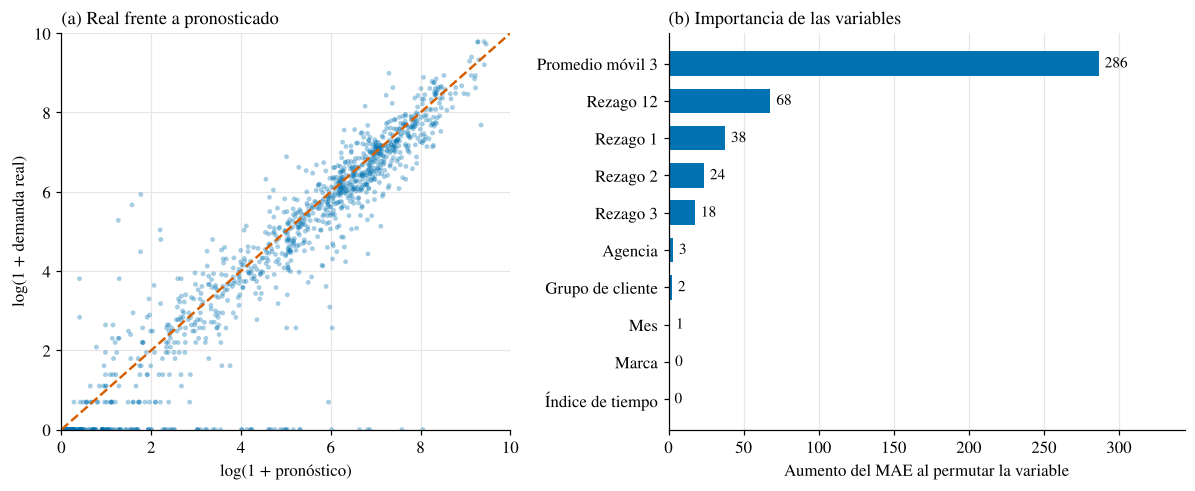

In [27]:
# =========================================
# 6.4 Figura 11: real frente a pronosticado e importancia por permutación
# =========================================
entrena, valida, prueba = particion(1, 'lag12')
entrena_valida = pd.concat([entrena, valida])
rf = modelo_rf(PARAMS[1]['RF']).fit(matriz(entrena_valida, 'lag12'), entrena_valida.unidades)
X_prueba = matriz(prueba, 'lag12')
y_prueba = prueba.unidades.values
mae_base = np.abs(np.clip(rf.predict(X_prueba), 0, None) - y_prueba).mean()

grupos_variables = {'Promedio móvil 3': ['ma3'], 'Rezago 12': ['lag12'], 'Rezago 1': ['lag1'], 'Rezago 2': ['lag2'],
                    'Rezago 3': ['lag3'], 'Mes': ['mes_cal'], 'Índice de tiempo': ['t'],
                    'Agencia': [c for c in X_prueba.columns if c.startswith('agencia_')],
                    'Grupo de cliente': [c for c in X_prueba.columns if c.startswith('grupo_')],
                    'Marca': [c for c in X_prueba.columns if c.startswith('marca_')]}
rng = np.random.default_rng(SEED)
importancia = {}
for nombre, cols in grupos_variables.items():
    aumentos = []
    for _ in range(10):                                             # 10 permutaciones por variable
        X_perm = X_prueba.copy()
        X_perm[cols] = X_prueba[cols].values[rng.permutation(len(X_prueba))]
        aumentos.append(np.abs(np.clip(rf.predict(X_perm), 0, None) - y_prueba).mean() - mae_base)
    importancia[nombre] = np.mean(aumentos)
importancia = pd.Series(importancia).sort_values(ascending=False)
print('Aumento del MAE al permutar cada variable:')
print(importancia.round(1))

f_rf = RES[(1, 'lag12', 'RF')]['test']
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={'width_ratios': [1, 1.15]})
a.scatter(np.log1p(f_rf), np.log1p(yt[1]), s=10, color=AZUL, alpha=.35, edgecolor='none')
a.plot([0, 10], [0, 10], color=NARANJA, ls='--', lw=1.6)
a.set_xlabel('log(1 + pronóstico)')
a.set_ylabel('log(1 + demanda real)')
a.set_title('(a) Real frente a pronosticado', loc='left', fontsize=12)
a.set_xlim(0, 10)
a.set_ylim(0, 10)
cuadricula(a, 'both')

b.barh(importancia.index, importancia.values, color=AZUL, height=.66)
for i, v in enumerate(importancia.values):
    b.text(max(v, 0) + 4, i, f'{v:.0f}', va='center', fontsize=10)
b.invert_yaxis()
b.set_xlabel('Aumento del MAE al permutar la variable')
b.set_title('(b) Importancia de las variables', loc='left', fontsize=12)
b.set_xlim(0, importancia.max() * 1.2)
cuadricula(b, 'x')
fig.tight_layout()
guardar(fig, 'figura11_real_vs_pronostico_e_importancia')

## 7. Implicaciones para la organización

Esta sección traduce los resultados a decisiones: cuánto vale el error en dólares, qué se pronostica para septiembre a noviembre de 2026 y con qué método conviene pedir cada marca.

**Valor del error de pronóstico (ecuaciones 14 y 15)**

Con $p_j$ el precio medio de venta por unidad display de la marca en 2026, el valor del error por exceso es $\sum_j p_j \max(\hat y_j - y_j, 0)$ y por faltante $\sum_j p_j \max(y_j - \hat y_j, 0)$, sobre las 288 combinaciones de mes, agencia y marca de la prueba. Es el error valorado **al precio de venta**: sirve para comparar modelos y dimensionar el problema, no es un ahorro ni un costo de inventario.

In [28]:
# =========================================
# 7.1 Valor del error en dólares (Figura 12)
# =========================================
PRECIO = pd.read_csv(ruta + 'precios_medios_2026.csv').set_index('marca').precio_medio_2026
print('Precio medio por unidad display, 2026 (US$):')
print(PRECIO.round(2).sort_values().to_dict())

modelos_valor = {'Naive (mes anterior)': BASE[1]['Ingenuo (mes anterior)'],
                 'Naive estacional': BASE[1]['Ingenuo estacional'],
                 'Promedio móvil 3': BASE[1]['Promedio móvil 3'],
                 'Regresión lineal + rezago 12': RES[(1, 'lag12', 'LR')]['test'],
                 'Random Forest + rezago 12': RES[(1, 'lag12', 'RF')]['test'],
                 'XGBoost + rezago 12': RES[(1, 'lag12', 'XGB')]['test']}

valor = PRUEBA[1][['agencia', 'marca', 't', 'unidades']].copy()
for nombre, f in modelos_valor.items():
    valor[nombre] = f
comb = valor.groupby(['agencia', 'marca', 't']).sum().reset_index()       # 72 agencia-marca × 4 meses
comb['precio'] = comb.marca.map(PRECIO)
print(f"\nCombinaciones evaluadas: {len(comb)} · venta real valorada: US$ {(comb.unidades * comb.precio).sum() / 1e6:.2f} millones")

tabla_valor = {}
for nombre in modelos_valor:
    exceso = comb.precio * np.maximum(comb[nombre] - comb.unidades, 0)
    faltante = comb.precio * np.maximum(comb.unidades - comb[nombre], 0)
    tabla_valor[nombre] = {'Exceso': exceso.sum() / 1e3, 'Faltante': faltante.sum() / 1e3, 'Total': (exceso + faltante).sum() / 1e3}
tabla_valor = pd.DataFrame(tabla_valor).T.sort_values('Total')
tabla_valor.round(0).to_csv('salidas/figura12_valor_error.csv')
print('\n=== VALOR DEL ERROR (miles de US$) ===')
print(tabla_valor.round(0))

rf_total = tabla_valor.loc['Random Forest + rezago 12', 'Total']
naive_total = tabla_valor.loc['Naive (mes anterior)', 'Total']
print(f"\nRandom Forest frente al ingenuo: -{(1 - rf_total / naive_total) * 100:.1f} % (US$ {naive_total - rf_total:,.0f} mil)")
print(f"Porcentaje del error de Random Forest que es por exceso: {tabla_valor.loc['Random Forest + rezago 12', 'Exceso'] / rf_total * 100:.0f} %")

error_mensual = {n: comb.assign(e=comb.precio * np.abs(comb[n] - comb.unidades)).groupby('t').e.sum() for n in modelos_valor}
for n in ('Naive (mes anterior)', 'Naive estacional', 'Promedio móvil 3'):
    ganados = int((error_mensual['Random Forest + rezago 12'] < error_mensual[n]).sum())
    print(f'Meses (de 4) en que Random Forest tiene menor error valorado que {n}: {ganados}')

Precio medio por unidad display, 2026 (US$):
{'NOGGY': 2.59, 'KINDER BUENO': 3.24, 'RAFFAELLO': 4.23, 'ROCHER': 4.87, 'NUTELLA': 5.05, 'HANUTA': 5.22, 'TIC TAC': 5.28, 'KINDER CHOCOLATE': 7.23, 'KINDER JOY': 10.64}

Combinaciones evaluadas: 288 · venta real valorada: US$ 4.99 millones

=== VALOR DEL ERROR (miles de US$) ===
                              Exceso  Faltante   Total
Regresión lineal + rezago 12   876.0     528.0  1404.0
Random Forest + rezago 12      952.0     458.0  1411.0
Naive estacional               871.0     617.0  1489.0
Promedio móvil 3              1037.0     473.0  1509.0
XGBoost + rezago 12            971.0     557.0  1528.0
Naive (mes anterior)          1007.0     658.0  1665.0

Random Forest frente al ingenuo: -15.3 % (US$ 254 mil)
Porcentaje del error de Random Forest que es por exceso: 68 %
Meses (de 4) en que Random Forest tiene menor error valorado que Naive (mes anterior): 3
Meses (de 4) en que Random Forest tiene menor error valorado que Naive estacional:

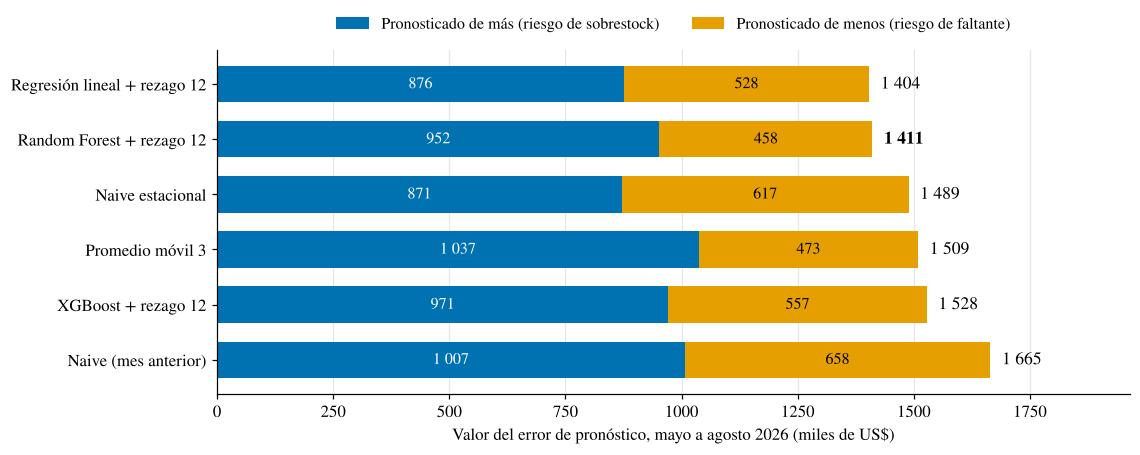

In [29]:
# =========================================
# 7.2 Figura 12
# =========================================
mil = lambda v: f'{v:,.0f}'.replace(',', ' ')
fig, ax = plt.subplots(figsize=(10.5, 4.3))
y = np.arange(len(tabla_valor))
ax.barh(y, tabla_valor.Exceso, color=AZUL, height=.66, label='Pronosticado de más (riesgo de sobrestock)')
ax.barh(y, tabla_valor.Faltante, left=tabla_valor.Exceso, color=AMARILLO, height=.66,
        label='Pronosticado de menos (riesgo de faltante)')
for i, (e, f_, t_) in enumerate(zip(tabla_valor.Exceso, tabla_valor.Faltante, tabla_valor.Total)):
    ax.text(e / 2, i, mil(e), ha='center', va='center', color='white', fontsize=10.5)
    ax.text(e + f_ / 2, i, mil(f_), ha='center', va='center', fontsize=10.5)
    ax.text(t_ + 25, i, mil(t_), va='center', fontsize=11.5,
            fontweight='bold' if tabla_valor.index[i] == 'Random Forest + rezago 12' else 'normal')
ax.set_yticks(y)
ax.set_yticklabels(tabla_valor.index)
ax.invert_yaxis()
ax.set_xlim(0, tabla_valor.Total.max() * 1.18)
ax.set_xlabel('Valor del error de pronóstico, mayo a agosto 2026 (miles de US$)')
ax.legend(ncol=2, loc='upper center', bbox_to_anchor=(.5, 1.14), fontsize=10.5)
cuadricula(ax, 'x')
fig.tight_layout()
guardar(fig, 'figura12_valor_del_error')

**Pronóstico de septiembre a noviembre de 2026**

El modelo de cada horizonte (Random Forest con rezago de 12 meses y los hiperparámetros de la Tabla 6) se reentrena con todos los meses cerrados, hasta agosto de 2026, y pronostica septiembre (1 mes), octubre (2 meses) y noviembre (3 meses) para cada serie. Los pronósticos se suman a nivel de agencia y marca, que es donde se decide la reposición a las agencias.

In [30]:
# =========================================
# 7.3 Pronóstico por serie y agregación a agencia × marca
# =========================================
MESES_FUTURO = {1: (32, 'Septiembre 2026'), 2: (33, 'Octubre 2026'), 3: (34, 'Noviembre 2026')}   # t = 32 → septiembre
Y = panel.pivot(index='serie', columns='t', values='unidades')
META = panel.drop_duplicates('serie').set_index('serie')[['agencia', 'grupo', 'marca']]

bloques = []
for h, (t_objetivo, etiqueta) in MESES_FUTURO.items():
    entrena = DATOS[h][(DATOS[h].t >= 12) & (DATOS[h].t <= 31)]       # todo el historial cerrado
    futuro = META.copy()
    futuro['lag1'] = Y[t_objetivo - h]
    futuro['lag2'] = Y[t_objetivo - h - 1]
    futuro['lag3'] = Y[t_objetivo - h - 2]
    futuro['ma3'] = futuro[['lag1', 'lag2', 'lag3']].mean(axis=1)
    futuro['lag12'] = Y[t_objetivo - 12]                              # venta del mismo mes de 2025
    futuro['mes_cal'] = t_objetivo % 12 + 1
    futuro['t'] = t_objetivo
    futuro = futuro.reset_index()
    futuro['pronostico'] = ajustar_predecir('RF', PARAMS[h]['RF'], entrena, futuro, 'lag12')
    futuro['mes_texto'] = etiqueta
    futuro['h'] = h
    bloques.append(futuro[['mes_texto', 'h', 't', 'agencia', 'grupo', 'marca', 'pronostico', 'lag12']])
FUTURO = pd.concat(bloques, ignore_index=True)

fam = FUTURO.groupby(['mes_texto', 'h', 'agencia', 'marca'], as_index=False).agg(
    pronostico=('pronostico', 'sum'), ano_anterior=('lag12', 'sum'))
promedio_3m = panel[panel.t >= 29].groupby(['agencia', 'marca']).unidades.sum() / 3     # junio a agosto de 2026
fam['prom3'] = [promedio_3m.get((a, m), 0) for a, m in zip(fam.agencia, fam.marca)]
fam = fam.sort_values(['h', 'agencia', 'marca']).reset_index(drop=True)
print(len(fam), 'filas =', fam.groupby('h').size().to_dict(), '(agencia × marca por mes)')

216 filas = {1: 72, 2: 72, 3: 72} (agencia × marca por mes)


**Tabla 12. Pronóstico nacional**

La alerta marca una fila cuando el pronóstico se aleja más de 30 % de lo vendido el mismo mes de 2025. El valor se calcula con el precio medio de venta por unidad display de 2026.

In [31]:
# =========================================
# 7.4 Tabla 12: pronóstico nacional, septiembre a noviembre de 2026
# =========================================
fam['precio'] = fam.marca.map(PRECIO)
fam['valor'] = fam.pronostico * fam.precio
fam['variacion'] = fam.pronostico / fam.ano_anterior.replace(0, np.nan) - 1
fam['alerta'] = fam.variacion.abs() > .30

tabla12 = fam.groupby('mes_texto', sort=False).agg(**{
    'Pronóstico (u.)': ('pronostico', 'sum'), 'Mismo mes 2025 (u.)': ('ano_anterior', 'sum'),
    'Valor (millones US$)': ('valor', lambda s: s.sum() / 1e6), 'Filas con alerta': ('alerta', 'sum')})
tabla12['Variación (%)'] = (tabla12['Pronóstico (u.)'] / tabla12['Mismo mes 2025 (u.)'] - 1) * 100
tabla12 = tabla12[['Pronóstico (u.)', 'Mismo mes 2025 (u.)', 'Variación (%)', 'Valor (millones US$)', 'Filas con alerta']]
tabla12.round(2).to_csv('salidas/tabla12_pronostico_nacional.csv')
print('=== TABLA 12. PRONÓSTICO NACIONAL ===')
print(tabla12.round(2))

agosto = panel[panel.t == 31].unidades.sum()
septiembre = tabla12['Pronóstico (u.)'].iloc[0]
acum_2026 = panel[(panel.t >= 24) & (panel.t <= 31)].unidades.sum()
acum_2025 = panel[(panel.t >= 12) & (panel.t <= 19)].unidades.sum()
print(f'\nSeptiembre frente a agosto ({agosto:,.0f} u.): {septiembre / agosto - 1:+.1%}')
print(f'Ventas de enero a agosto de 2026 frente a 2025: {acum_2026 / acum_2025 - 1:+.1%}')

=== TABLA 12. PRONÓSTICO NACIONAL ===
                 Pronóstico (u.)  Mismo mes 2025 (u.)  Variación (%)  \
mes_texto                                                              
Septiembre 2026        219659.78            244911.56         -10.31   
Octubre 2026           221657.94            249887.38         -11.30   
Noviembre 2026         241729.90            294853.60         -18.02   

                 Valor (millones US$)  Filas con alerta  
mes_texto                                                
Septiembre 2026                  1.22                14  
Octubre 2026                     1.21                26  
Noviembre 2026                   1.35                25  

Septiembre frente a agosto (214,266 u.): +2.5%
Ventas de enero a agosto de 2026 frente a 2025: -7.2%


**Tabla 13. Método recomendado por marca**

Para cada marca se compara el WAPE de la prueba (por agencia, marca y mes) del modelo contra el de las reglas simples. La regla de decisión es: si la venta del mismo mes del año anterior tiene un WAPE al menos 0,10 menor que el del modelo, se usa esa venta; en otro caso se usa el modelo, con pedidos pequeños y frecuentes si su WAPE supera 0,40.

In [32]:
# =========================================
# 7.5 Tabla 13: método recomendado por marca
# =========================================
año_anterior = PRUEBA[1].groupby(['agencia', 'marca', 't']).lag12.sum().reset_index()
comb['Año anterior'] = comb.merge(año_anterior, on=['agencia', 'marca', 't'], how='left').lag12.values

def wape_marca(columna):
    return comb.groupby('marca').apply(lambda d: np.abs(d[columna] - d.unidades).sum() / d.unidades.sum())

tabla13 = pd.DataFrame({'Unidades vendidas': comb.groupby('marca').unidades.sum(),
                        'Modelo': wape_marca('Random Forest + rezago 12'),
                        'Mes anterior': wape_marca('Naive (mes anterior)'),
                        'Año anterior': wape_marca('Año anterior'),
                        'Prom. móvil 3': wape_marca('Promedio móvil 3')})

def metodo_recomendado(fila):
    if fila['Modelo'] - fila['Año anterior'] >= .10:
        return 'Venta del mismo mes del año anterior'
    if fila['Modelo'] > .40:
        return 'Modelo, con pedidos pequeños y frecuentes'
    return 'Modelo'

tabla13['Método recomendado'] = tabla13.apply(metodo_recomendado, axis=1)
tabla13 = tabla13.sort_values('Modelo')
tabla13.round(3).to_csv('salidas/tabla13_metodo_por_marca.csv')
print('=== TABLA 13. MÉTODO RECOMENDADO POR MARCA ===')
print(tabla13.round(3))

usa_modelo = tabla13[tabla13['Método recomendado'] == 'Modelo']
print(f"\nMarcas con 'Modelo': {list(usa_modelo.index)} → {usa_modelo['Unidades vendidas'].sum() / tabla13['Unidades vendidas'].sum() * 100:.0f} % de las unidades de la prueba")

# Alertas en la prueba: ¿las filas con alerta tienen más error?
comb['alerta'] = (comb['Random Forest + rezago 12'] / comb['Año anterior'].replace(0, np.nan) - 1).abs() > .30
wape_grupo = lambda d: np.abs(d['Random Forest + rezago 12'] - d.unidades).sum() / d.unidades.sum()
print(f"Prueba: {int(comb.alerta.sum())} combinaciones con alerta (WAPE {wape_grupo(comb[comb.alerta]):.2f}) "
      f"frente a {int((~comb.alerta).sum())} sin alerta (WAPE {wape_grupo(comb[~comb.alerta]):.2f})")

=== TABLA 13. MÉTODO RECOMENDADO POR MARCA ===
                  Unidades vendidas  Modelo  Mes anterior  Año anterior  \
marca                                                                     
KINDER CHOCOLATE          20570.042   0.151         0.227         0.240   
TIC TAC                   63721.000   0.173         0.236         0.217   
KINDER BUENO              68720.333   0.196         0.284         0.265   
NUTELLA                  248795.150   0.237         0.273         0.246   
KINDER JOY               142473.750   0.262         0.298         0.297   
ROCHER                   175906.562   0.342         0.445         0.224   
HANUTA                    51062.000   0.417         0.432         0.521   
RAFFAELLO                 41606.125   0.465         0.636         0.341   
NOGGY                     82191.000   0.495         0.402         0.803   

                  Prom. móvil 3                         Método recomendado  
marca                                             

**Libro de Excel de apoyo a la planificación**

Se genera un libro con cinco hojas: *Léame*, *Pronóstico* (216 filas, con alerta, bandas, confiabilidad, método recomendado y valor estimado), *Totales*, *Desempeño* y *Parámetros*. Las columnas calculadas son fórmulas de Excel, así que al cambiar un parámetro (por ejemplo el umbral de alerta o los precios) se recalculan solas.

In [33]:
# =========================================
# 7.6 Libro de Excel: Herramienta_Pronostico_Asertia.xlsx
# =========================================
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.formatting.rule import FormulaRule
from openpyxl.utils import get_column_letter

wb = Workbook()
FONDO_ENCABEZADO = PatternFill('solid', fgColor='1F4E79')
FONDO_EDITABLE = PatternFill('solid', fgColor='FFF2CC')

def encabezado(ws, fila, textos):
    for j, texto in enumerate(textos, 1):
        c = ws.cell(fila, j, texto)
        c.font = Font(bold=True, color='FFFFFF')
        c.fill = FONDO_ENCABEZADO
        c.alignment = Alignment(horizontal='center', vertical='center', wrap_text=True)
    ws.row_dimensions[fila].height = 32

def anchos(ws, lista):
    for j, ancho in enumerate(lista, 1):
        ws.column_dimensions[get_column_letter(j)].width = ancho

# --- Hoja Léame
ws = wb.active
ws.title = 'Léame'
lineas = ['Herramienta de pronóstico de ventas — Asertia Comercial, línea Ferrero', '',
          'Qué contiene: pronóstico mensual de unidades display de septiembre a noviembre de 2026 por agencia y marca (72 combinaciones por mes, 216 filas).',
          'Modelo: Random Forest con rezago de 12 meses, reentrenado con los datos cerrados hasta agosto de 2026 (ver cuaderno de Colab).',
          'Hojas: Parámetros (celdas amarillas editables), Pronóstico, Totales y Desempeño. Lo calculado con fórmulas se actualiza al cambiar los parámetros.',
          'Alerta: la fila se marca «Revisar» cuando el pronóstico se aleja más del umbral de lo vendido el mismo mes de 2025. Revisarlas a mano antes de pedir.',
          'Confiabilidad y método: salen del WAPE de la marca en la prueba (mayo a agosto de 2026). Conviene revisarlos cada trimestre.',
          'Valor estimado: pronóstico × precio medio de venta por unidad display de 2026. No es costo de inventario ni margen.',
          'Reentrenar al cerrar cada mes con la venta completa.']
for i, texto in enumerate(lineas, 1):
    ws.cell(i, 1, texto).font = Font(bold=(i == 1), size=13 if i == 1 else 11)
ws.column_dimensions['A'].width = 140

# --- Hoja Parámetros
wp = wb.create_sheet('Parámetros')
wp['A1'] = 'Parámetros (celdas amarillas editables)'
wp['A1'].font = Font(bold=True, size=13)
parametros = [('Umbral de alerta frente al mismo mes de 2025', .30, '0%'),
              ('WAPE máximo para confiabilidad «Alta»', .20, '0.00'),
              ('WAPE máximo para confiabilidad «Media»', .40, '0.00'),
              ('Ventaja mínima del año anterior sobre el modelo (puntos de WAPE)', .10, '0.00'),
              ('WAPE desde el cual se piden lotes pequeños y frecuentes', .40, '0.00'),
              ('Factor de la banda (× WAPE de la marca)', 1.0, '0.00')]
for i, (nombre, valor_p, formato) in enumerate(parametros, 3):
    wp.cell(i, 1, nombre)
    c = wp.cell(i, 2, valor_p)
    c.number_format = formato
    c.fill = FONDO_EDITABLE
wp['A11'] = 'Precio medio por unidad display, 2026 (US$)'
wp['A11'].font = Font(bold=True)
encabezado(wp, 12, ['Marca', 'Precio (US$)'])
for i, (marca, precio) in enumerate(PRECIO.sort_index().items(), 13):
    wp.cell(i, 1, marca.title())
    c = wp.cell(i, 2, float(precio))
    c.number_format = '0.00'
    c.fill = FONDO_EDITABLE
anchos(wp, [62, 16])
ULTIMA_PRECIO = 13 + len(PRECIO) - 1

# --- Hoja Desempeño (Tabla 13)
wd = wb.create_sheet('Desempeño')
wd['A1'] = 'WAPE de la prueba (mayo a agosto de 2026), por agencia, marca y mes'
wd['A1'].font = Font(bold=True, size=13)
encabezado(wd, 3, ['Marca', 'Unidades vendidas', 'Modelo', 'Mes anterior', 'Año anterior', 'Prom. móvil 3',
                   'Método recomendado', 'Confiabilidad'])
for i, (marca, fila) in enumerate(tabla13.iterrows(), 4):
    wd.cell(i, 1, marca.title())
    wd.cell(i, 2, float(fila['Unidades vendidas'])).number_format = '#,##0'
    for j, col in zip(range(3, 7), ['Modelo', 'Mes anterior', 'Año anterior', 'Prom. móvil 3']):
        wd.cell(i, j, round(float(fila[col]), 3)).number_format = '0.000'
    wd.cell(i, 7, f'=IF(C{i}-E{i}>=Parámetros!$B$6,"Venta del mismo mes del año anterior",'
                  f'IF(C{i}>Parámetros!$B$7,"Modelo, con pedidos pequeños y frecuentes","Modelo"))')
    wd.cell(i, 8, f'=IF(C{i}<=Parámetros!$B$4,"Alta",IF(C{i}<=Parámetros!$B$5,"Media","Baja"))')
anchos(wd, [20, 18, 11, 13, 13, 14, 44, 15])
ULTIMA_DESEMPENO = 4 + len(tabla13) - 1

# --- Hoja Pronóstico
wf = wb.create_sheet('Pronóstico')
encabezado(wf, 1, ['Mes', 'Agencia', 'Marca', 'Pronóstico (u.)', 'Mismo mes 2025 (u.)', 'Prom. 3 meses previos (u.)',
                   'Variación vs 2025', 'Alerta', 'WAPE de la marca', 'Banda inferior (u.)', 'Banda superior (u.)',
                   'Confiabilidad', 'Método recomendado', 'Precio (US$)', 'Valor estimado (US$)'])
D = ULTIMA_DESEMPENO
for i, r in enumerate(fam.itertuples(), 2):
    wf.cell(i, 1, r.mes_texto)
    wf.cell(i, 2, r.agencia.title())
    wf.cell(i, 3, r.marca.title())
    wf.cell(i, 4, round(float(r.pronostico), 1)).number_format = '#,##0'
    wf.cell(i, 5, float(r.ano_anterior)).number_format = '#,##0'
    wf.cell(i, 6, round(float(r.prom3), 1)).number_format = '#,##0'
    wf.cell(i, 7, f'=IF(E{i}=0,"",D{i}/E{i}-1)').number_format = '0.0%'
    wf.cell(i, 8, f'=IF(E{i}=0,IF(D{i}>0,"Revisar",""),IF(ABS(G{i})>Parámetros!$B$3,"Revisar",""))')
    wf.cell(i, 9, f'=INDEX(Desempeño!$C$4:$C${D},MATCH(C{i},Desempeño!$A$4:$A${D},0))').number_format = '0.000'
    wf.cell(i, 10, f'=MAX(0,D{i}*(1-I{i}*Parámetros!$B$8))').number_format = '#,##0'
    wf.cell(i, 11, f'=D{i}*(1+I{i}*Parámetros!$B$8)').number_format = '#,##0'
    wf.cell(i, 12, f'=INDEX(Desempeño!$H$4:$H${D},MATCH(C{i},Desempeño!$A$4:$A${D},0))')
    wf.cell(i, 13, f'=INDEX(Desempeño!$G$4:$G${D},MATCH(C{i},Desempeño!$A$4:$A${D},0))')
    wf.cell(i, 14, f'=INDEX(Parámetros!$B$13:$B${ULTIMA_PRECIO},MATCH(C{i},Parámetros!$A$13:$A${ULTIMA_PRECIO},0))').number_format = '0.00'
    wf.cell(i, 15, f'=D{i}*N{i}').number_format = '#,##0'
N = len(fam) + 1
wf.freeze_panes = 'D2'
wf.auto_filter.ref = f'A1:O{N}'
anchos(wf, [18, 15, 17, 14, 14, 16, 13, 10, 11, 14, 14, 13, 40, 11, 16])
wf.conditional_formatting.add(f'A2:O{N}', FormulaRule(formula=['$H2="Revisar"'], fill=PatternFill('solid', bgColor='FCE4D6')))

# --- Hoja Totales
wt = wb.create_sheet('Totales')
wt['A1'] = 'Pronóstico nacional por mes'
wt['A1'].font = Font(bold=True, size=13)
encabezado(wt, 3, ['Mes', 'Pronóstico (u.)', 'Mismo mes 2025 (u.)', 'Variación', 'Valor (millones US$)', 'Filas con alerta'])
etiquetas_mes = [v[1] for v in MESES_FUTURO.values()]
for i, mes in enumerate(etiquetas_mes, 4):
    wt.cell(i, 1, mes)
    wt.cell(i, 2, f'=SUMIFS(Pronóstico!$D$2:$D${N},Pronóstico!$A$2:$A${N},A{i})').number_format = '#,##0'
    wt.cell(i, 3, f'=SUMIFS(Pronóstico!$E$2:$E${N},Pronóstico!$A$2:$A${N},A{i})').number_format = '#,##0'
    wt.cell(i, 4, f'=B{i}/C{i}-1').number_format = '0.0%'
    wt.cell(i, 5, f'=SUMIFS(Pronóstico!$O$2:$O${N},Pronóstico!$A$2:$A${N},A{i})/1000000').number_format = '0.00'
    wt.cell(i, 6, f'=COUNTIFS(Pronóstico!$A$2:$A${N},A{i},Pronóstico!$H$2:$H${N},"Revisar")&" de "&COUNTIFS(Pronóstico!$A$2:$A${N},A{i})')

wt['A9'] = 'Pronóstico por marca (u.)'
wt['A9'].font = Font(bold=True, size=12)
encabezado(wt, 10, ['Marca'] + etiquetas_mes)
for i, marca in enumerate(sorted(fam.marca.unique()), 11):
    wt.cell(i, 1, marca.title())
    for j in range(2, 5):
        letra = get_column_letter(j)
        wt.cell(i, j, f'=SUMIFS(Pronóstico!$D$2:$D${N},Pronóstico!$C$2:$C${N},$A{i},Pronóstico!$A$2:$A${N},{letra}$10)').number_format = '#,##0'

fila0 = 11 + fam.marca.nunique() + 1
wt.cell(fila0, 1, 'Pronóstico por agencia (u.)').font = Font(bold=True, size=12)
encabezado(wt, fila0 + 1, ['Agencia'] + etiquetas_mes)
for i, agencia in enumerate(sorted(fam.agencia.unique()), fila0 + 2):
    wt.cell(i, 1, agencia.title())
    for j in range(2, 5):
        letra = get_column_letter(j)
        wt.cell(i, j, f'=SUMIFS(Pronóstico!$D$2:$D${N},Pronóstico!$B$2:$B${N},$A{i},Pronóstico!$A$2:$A${N},{letra}${fila0 + 1})').number_format = '#,##0'
anchos(wt, [24, 18, 20, 14, 20, 17])

wb._sheets = [wb['Léame'], wb['Pronóstico'], wb['Totales'], wb['Desempeño'], wb['Parámetros']]
wb.save('salidas/Herramienta_Pronostico_Asertia.xlsx')
print('Libro guardado en salidas/Herramienta_Pronostico_Asertia.xlsx')

Libro guardado en salidas/Herramienta_Pronostico_Asertia.xlsx


## Referencias

- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32. https://doi.org/10.1023/A:1010933404324
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785-794. https://doi.org/10.1145/2939672.2939785
- Dickey, D. A., & Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. *Journal of the American Statistical Association, 74*(366), 427-431.
- Efron, B. (1979). Bootstrap methods: Another look at the jackknife. *The Annals of Statistics, 7*(1), 1-26.
- Hyndman, R. J., & Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of Forecasting, 22*(4), 679-688.
- Pérez Muso, Z. (2025). *Pronóstico de la demanda del repuesto Pulmón Doble Acción 30/30 mediante la comparación del método estadístico regresión lineal y métodos de machine learning (Random Forest y XGBoost)* [Tesis de maestría, Universidad de Las Américas].
- Ramsey, J. B. (1969). Tests for specification errors in classical linear least-squares regression analysis. *Journal of the Royal Statistical Society: Series B, 31*(2), 350-371.
- Wilcoxon, F. (1945). Individual comparisons by ranking methods. *Biometrics Bulletin, 1*(6), 80-83.